# EduPredict: Student Academic Performance Analysis and Prediction Using Machine Learning

**Subject:** Predictive Analytics  |  **Dataset:** Student Performance Factors (Kaggle, `StudentPerformanceFactors.csv`)  |  **Target:** `Exam_Score`

This notebook runs end-to-end: data cleaning, EDA, five objectives, feature engineering, four regression models, evaluation, best-model selection and saving the model used by the Streamlit app (`app.py`).
It works in Jupyter and Google Colab. In Colab, upload `StudentPerformanceFactors.csv` to the working folder first.

**Phases:** 1 Setup, 2 Understanding and preprocessing, 3 EDA and objectives, 4 Feature engineering, 5 Models, 6 Evaluation and best model, 7 Saving for the app, 8 Findings.

## Phase 1: Setup and dataset loading

In [1]:
import warnings
warnings.filterwarnings('ignore')

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import stats   # only used for correlation / ANOVA p-values (it is installed together with scikit-learn)

# --- paths (work from the notebooks/ folder, or from a flat Colab folder) ---
BASE = Path('..') if Path('../dataset').exists() else Path('.')
DATA = BASE / 'dataset' / 'StudentPerformanceFactors.csv'
if not DATA.exists():
    DATA = Path('StudentPerformanceFactors.csv')      # Colab: file uploaded next to the notebook
GRAPHS = BASE / 'outputs' / 'graphs'
MODELS = BASE / 'models'
for folder in (GRAPHS, MODELS):
    folder.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', palette='deep')

def save_fig(name):
    """Tidy the layout, save the figure into outputs/graphs and show it."""
    plt.tight_layout()
    plt.savefig(GRAPHS / name, dpi=130, bbox_inches='tight')
    plt.show()

RANDOM_STATE = 42
print('Dataset file:', DATA)

Dataset file: ../dataset/StudentPerformanceFactors.csv


## Phase 2: Dataset understanding and preprocessing

### 2.1 First look at the data

In [2]:
df = pd.read_csv(DATA)
print('First 5 rows')
display(df.head())
print()
print('Last 5 rows')
display(df.tail())
print()
print('Shape (rows, columns):', df.shape)

First 5 rows
   Hours_Studied  Attendance Parental_Involvement Access_to_Resources Extracurricular_Activities  Sleep_Hours  Previous_Scores Motivation_Level Internet_Access  Tutoring_Sessions Family_Income Teacher_Quality School_Type Peer_Influence  Physical_Activity Learning_Disabilities Parental_Education_Level Distance_from_Home  Gender  Exam_Score
0             23          84                  Low                High                         No            7               73              Low             Yes                  0           Low          Medium      Public       Positive                  3                    No              High School               Near    Male          67
1             19          64                  Low              Medium                         No            8               59              Low             Yes                  2        Medium          Medium      Public       Negative                  4                    No                  College    

In [3]:
print('Column names:')
print(list(df.columns))
print()
df.info()

Column names:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7

In [4]:
# Descriptive statistics of the numerical columns
df.describe().T.round(2)

                    count   mean    std   min   25%   50%   75%    max
Hours_Studied      6607.0  19.98   5.99   1.0  16.0  20.0  24.0   44.0
Attendance         6607.0  79.98  11.55  60.0  70.0  80.0  90.0  100.0
Sleep_Hours        6607.0   7.03   1.47   4.0   6.0   7.0   8.0   10.0
Previous_Scores    6607.0  75.07  14.40  50.0  63.0  75.0  88.0  100.0
Tutoring_Sessions  6607.0   1.49   1.23   0.0   1.0   1.0   2.0    8.0
Physical_Activity  6607.0   2.97   1.03   0.0   2.0   3.0   4.0    6.0
Exam_Score         6607.0  67.24   3.89  55.0  65.0  67.0  69.0  101.0

In [5]:
# Separate numerical and categorical features (target Exam_Score is excluded from both lists)
numeric_features = df.drop(columns='Exam_Score').select_dtypes(include='number').columns.tolist()
categorical_features = df.select_dtypes(exclude='number').columns.tolist()
print('Numerical features  (%d):' % len(numeric_features), numeric_features)
print('Categorical features (%d):' % len(categorical_features), categorical_features)

Numerical features  (6): ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']
Categorical features (13): ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


**Why:** Numerical and categorical columns need different treatment later (scaling for numbers, one-hot encoding for categories), so we identify them now. `Exam_Score` is the target we will predict.

### 2.2 Missing values and duplicates

In [6]:
missing = df.isnull().sum()
missing_report = pd.DataFrame({'missing_count': missing, 'missing_percent': (missing / len(df) * 100).round(2)})
print('Columns with missing values:')
print(missing_report[missing_report.missing_count > 0])
print()
print('Rows with at least one missing value:', df.isnull().any(axis=1).sum())
print('Duplicate rows:', df.duplicated().sum())

Columns with missing values:
                          missing_count  missing_percent
Teacher_Quality                      78             1.18
Parental_Education_Level             90             1.36
Distance_from_Home                   67             1.01

Rows with at least one missing value: 229
Duplicate rows: 0


**Findings.** Three categorical columns have missing values: `Teacher_Quality`, `Parental_Education_Level` and `Distance_from_Home`. They are small (about 1 to 1.4 percent each). No duplicate rows exist, so nothing is removed on that account (we did not add any artificially).

**Strategy.** Because the columns are categorical and the share missing is tiny, we fill with the **most frequent value (mode)**. Dropping the 229 incomplete rows would throw away useful data. For modelling, this is done *inside the scikit-learn pipeline* with `SimpleImputer`, so the fill values are learned from the training set only. For EDA, we fill a copy of the data with the mode so that plots are complete.

### 2.3 Inconsistent categories and invalid numerical values

In [7]:
# Inconsistent categories: look for spelling/case/space differences in each categorical column
for col in categorical_features:
    values = df[col].dropna()
    has_spaces = (values != values.str.strip()).sum()
    print(f'{col:28s} unique values: {sorted(values.unique())}  | values with stray spaces: {has_spaces}')

Parental_Involvement         unique values: ['High', 'Low', 'Medium']  | values with stray spaces: 0
Access_to_Resources          unique values: ['High', 'Low', 'Medium']  | values with stray spaces: 0
Extracurricular_Activities   unique values: ['No', 'Yes']  | values with stray spaces: 0
Motivation_Level             unique values: ['High', 'Low', 'Medium']  | values with stray spaces: 0
Internet_Access              unique values: ['No', 'Yes']  | values with stray spaces: 0
Family_Income                unique values: ['High', 'Low', 'Medium']  | values with stray spaces: 0
Teacher_Quality              unique values: ['High', 'Low', 'Medium']  | values with stray spaces: 0
School_Type                  unique values: ['Private', 'Public']  | values with stray spaces: 0
Peer_Influence               unique values: ['Negative', 'Neutral', 'Positive']  | values with stray spaces: 0
Learning_Disabilities        unique values: ['No', 'Yes']  | values with stray spaces: 0
Parental_Education_L

In [8]:
# Invalid numerical values: check each numeric column against a sensible valid range
valid_ranges = {
    'Hours_Studied': (0, 168),        # hours per week cannot exceed 168
    'Attendance': (0, 100),           # percentage
    'Sleep_Hours': (0, 24),
    'Previous_Scores': (0, 100),
    'Tutoring_Sessions': (0, None),
    'Physical_Activity': (0, None),
    'Exam_Score': (0, 100),
}
rows = []
for col, (low, high) in valid_ranges.items():
    bad = (df[col] < low).sum() + ((df[col] > high).sum() if high is not None else 0)
    rows.append({'column': col, 'min': df[col].min(), 'max': df[col].max(), 'valid_range': (low, high), 'invalid_rows': bad})
pd.DataFrame(rows)

              column  min  max valid_range  invalid_rows
0      Hours_Studied    1   44    (0, 168)             0
1         Attendance   60  100    (0, 100)             0
2        Sleep_Hours    4   10     (0, 24)             0
3    Previous_Scores   50  100    (0, 100)             0
4  Tutoring_Sessions    0    8   (0, None)             0
5  Physical_Activity    0    6   (0, None)             0
6         Exam_Score   55  101    (0, 100)             1

In [9]:
print('Rows with Exam_Score above 100:')
display(df[df['Exam_Score'] > 100])

Rows with Exam_Score above 100:
      Hours_Studied  Attendance Parental_Involvement Access_to_Resources Extracurricular_Activities  Sleep_Hours  Previous_Scores Motivation_Level Internet_Access  Tutoring_Sessions Family_Income Teacher_Quality School_Type Peer_Influence  Physical_Activity Learning_Disabilities Parental_Education_Level Distance_from_Home  Gender  Exam_Score
1525             27          98                  Low              Medium                        Yes            6               93              Low              No                  5          High            High      Public       Positive                  3                    No              High School           Moderate  Female         101


**Findings.** All categorical values are consistent (no spelling, case or spacing problems). Numerically, everything is valid except **one record with `Exam_Score = 101`**, which is impossible if scores are out of 100. This is a data-entry error, not an extreme-but-real value, so we remove that single row.

### 2.4 Outlier detection (box plots and IQR method)

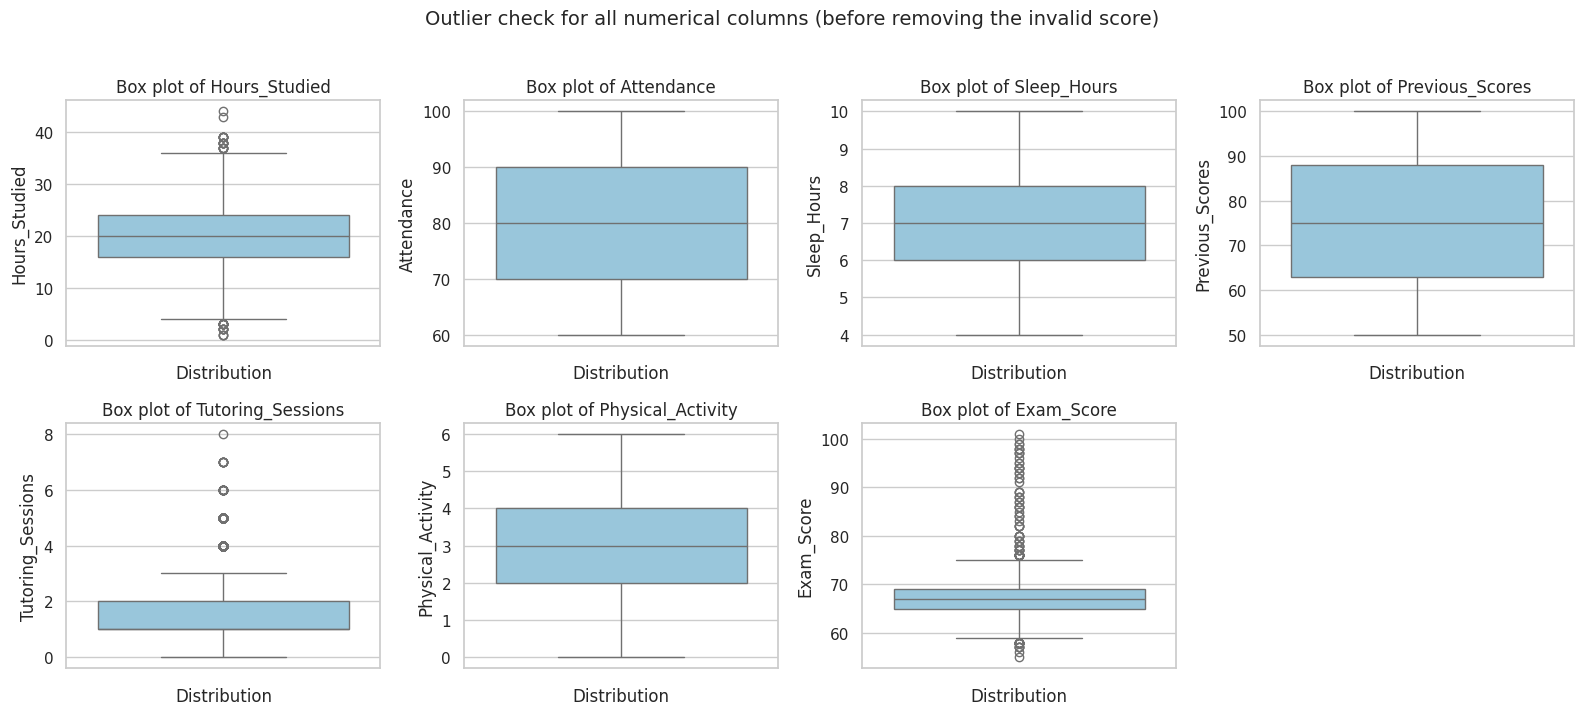

In [10]:
numeric_cols_all = numeric_features + ['Exam_Score']
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), numeric_cols_all):
    sns.boxplot(y=df[col], ax=ax, color='#8ecae6')
    ax.set_title(f'Box plot of {col}')
    ax.set_ylabel(col)
    ax.set_xlabel('Distribution')
axes.ravel()[-1].axis('off')
fig.suptitle('Outlier check for all numerical columns (before removing the invalid score)', y=1.02, fontsize=14)
save_fig('01_boxplots_outliers.png')

In [11]:
def iqr_outliers(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({'Q1': q1, 'Q3': q3, 'lower_fence': low, 'upper_fence': high,
                      'outlier_count': ((series < low) | (series > high)).sum()})

outlier_table = pd.DataFrame({col: iqr_outliers(df[col]) for col in numeric_cols_all}).T
outlier_table

                     Q1    Q3  lower_fence  upper_fence  outlier_count
Hours_Studied      16.0  24.0          4.0         36.0           43.0
Attendance         70.0  90.0         40.0        120.0            0.0
Sleep_Hours         6.0   8.0          3.0         11.0            0.0
Previous_Scores    63.0  88.0         25.5        125.5            0.0
Tutoring_Sessions   1.0   2.0         -0.5          3.5          430.0
Physical_Activity   2.0   4.0         -1.0          7.0            0.0
Exam_Score         65.0  69.0         59.0         75.0          104.0

**Decision on outliers.** The IQR rule flags values in `Hours_Studied`, `Tutoring_Sessions` and `Exam_Score` (the other columns have none). These flagged values are *valid* observations: a student studying 30+ hours a week, having 4+ tutoring sessions, or scoring 90 on a test is realistic. IQR only says a value is *unusual*, not *wrong*. So we **retain** them and remove only the impossible `Exam_Score = 101` row. Linear Regression can be influenced by extreme values, but tree-based models are not, and the flagged values are few relative to 6,600 rows.

In [12]:
# Build the cleaned dataset
df_clean = df[df['Exam_Score'] <= 100].copy()
print('Rows before:', len(df), '| rows after removing invalid score:', len(df_clean))

# EDA copy: fill missing categories with the mode (modelling pipelines do this separately, on training data only)
df_eda = df_clean.copy()
for col in ['Teacher_Quality', 'Parental_Education_Level', 'Distance_from_Home']:
    mode_value = df_eda[col].mode()[0]
    print(f'{col}: filling {df_eda[col].isnull().sum()} missing values with mode = {mode_value!r}')
    df_eda[col] = df_eda[col].fillna(mode_value)
print('Missing values left in EDA copy:', df_eda.isnull().sum().sum())

Rows before: 6607 | rows after removing invalid score: 6606
Teacher_Quality: filling 78 missing values with mode = 'Medium'
Parental_Education_Level: filling 90 missing values with mode = 'High School'
Distance_from_Home: filling 67 missing values with mode = 'Near'
Missing values left in EDA copy: 0


## Phase 3: Exploratory Data Analysis

### 3.1 Univariate analysis

count    6606.00
mean       67.23
std         3.87
min        55.00
25%        65.00
50%        67.00
75%        69.00
max       100.00
Name: Exam_Score, dtype: float64
Skewness: 1.58


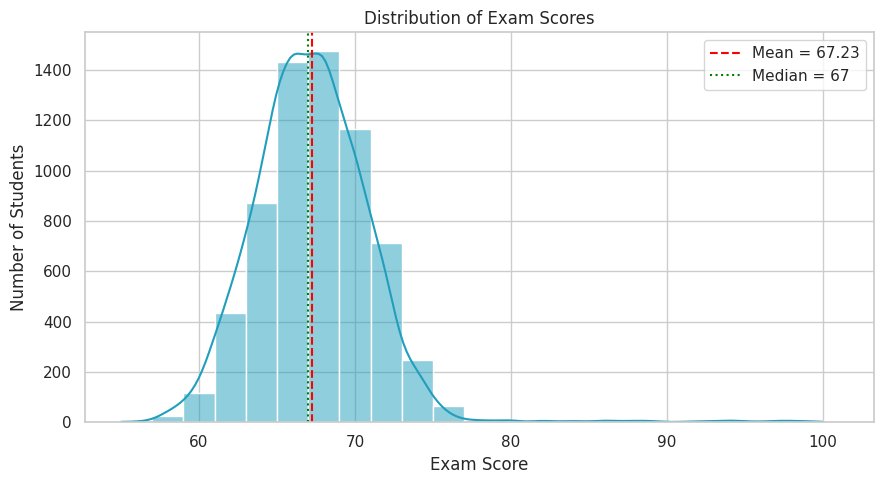

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df_eda['Exam_Score'], bins=range(55, 102, 2), kde=True, color='#219ebc', ax=ax)
ax.axvline(df_eda['Exam_Score'].mean(), color='red', linestyle='--', label=f"Mean = {df_eda['Exam_Score'].mean():.2f}")
ax.axvline(df_eda['Exam_Score'].median(), color='green', linestyle=':', label=f"Median = {df_eda['Exam_Score'].median():.0f}")
ax.set_title('Distribution of Exam Scores')
ax.set_xlabel('Exam Score')
ax.set_ylabel('Number of Students')
ax.legend()
save_fig('02_exam_score_distribution.png')
print(df_eda['Exam_Score'].describe().round(2))
print('Skewness:', round(df_eda['Exam_Score'].skew(), 2))

**Interpretation.** Exam scores are tightly concentrated: the average is about 67 and most students score between 65 and 69. The distribution is bell-shaped with a right tail (a few students reach the 80s and 90s). The narrow spread (standard deviation under 4 marks) means that even a small prediction error matters, which is why we measure errors in marks (MAE, RMSE) later.

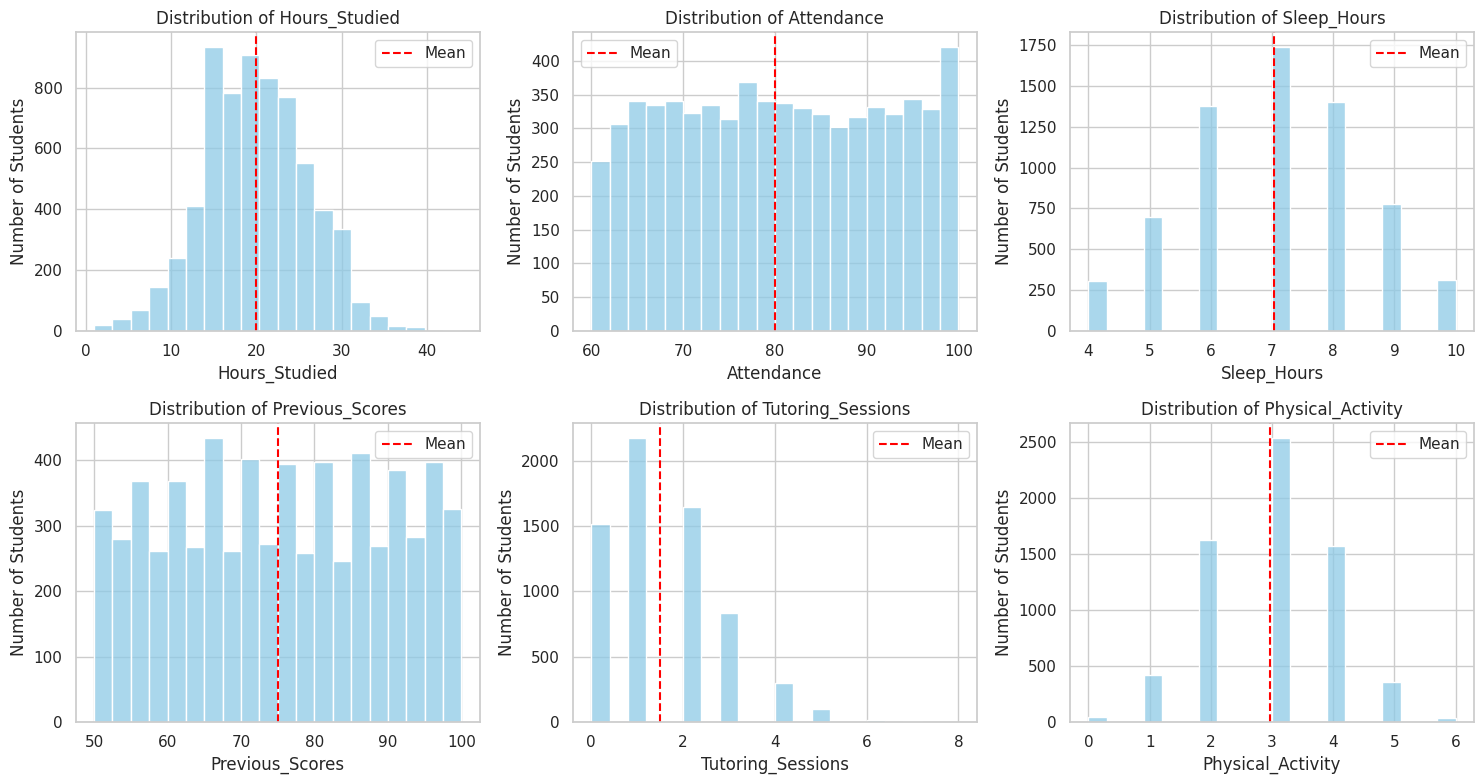

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), numeric_features):
    sns.histplot(df_eda[col], bins=20, kde=False, color='#8ecae6', ax=ax)
    ax.axvline(df_eda[col].mean(), color='red', linestyle='--', label='Mean')
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Number of Students')
    ax.legend()
save_fig('03_numeric_histograms.png')

**Interpretation.** `Hours_Studied` is roughly bell-shaped (centred near 20 hours a week). `Attendance` (60 to 100) and `Previous_Scores` (50 to 100) are spread fairly evenly across their ranges, `Sleep_Hours` clusters around 7, and `Tutoring_Sessions` is heavily concentrated at 0 to 2 with a thin tail up to 8. `Physical_Activity` centres near 3 hours. No feature is dominated by impossible values.

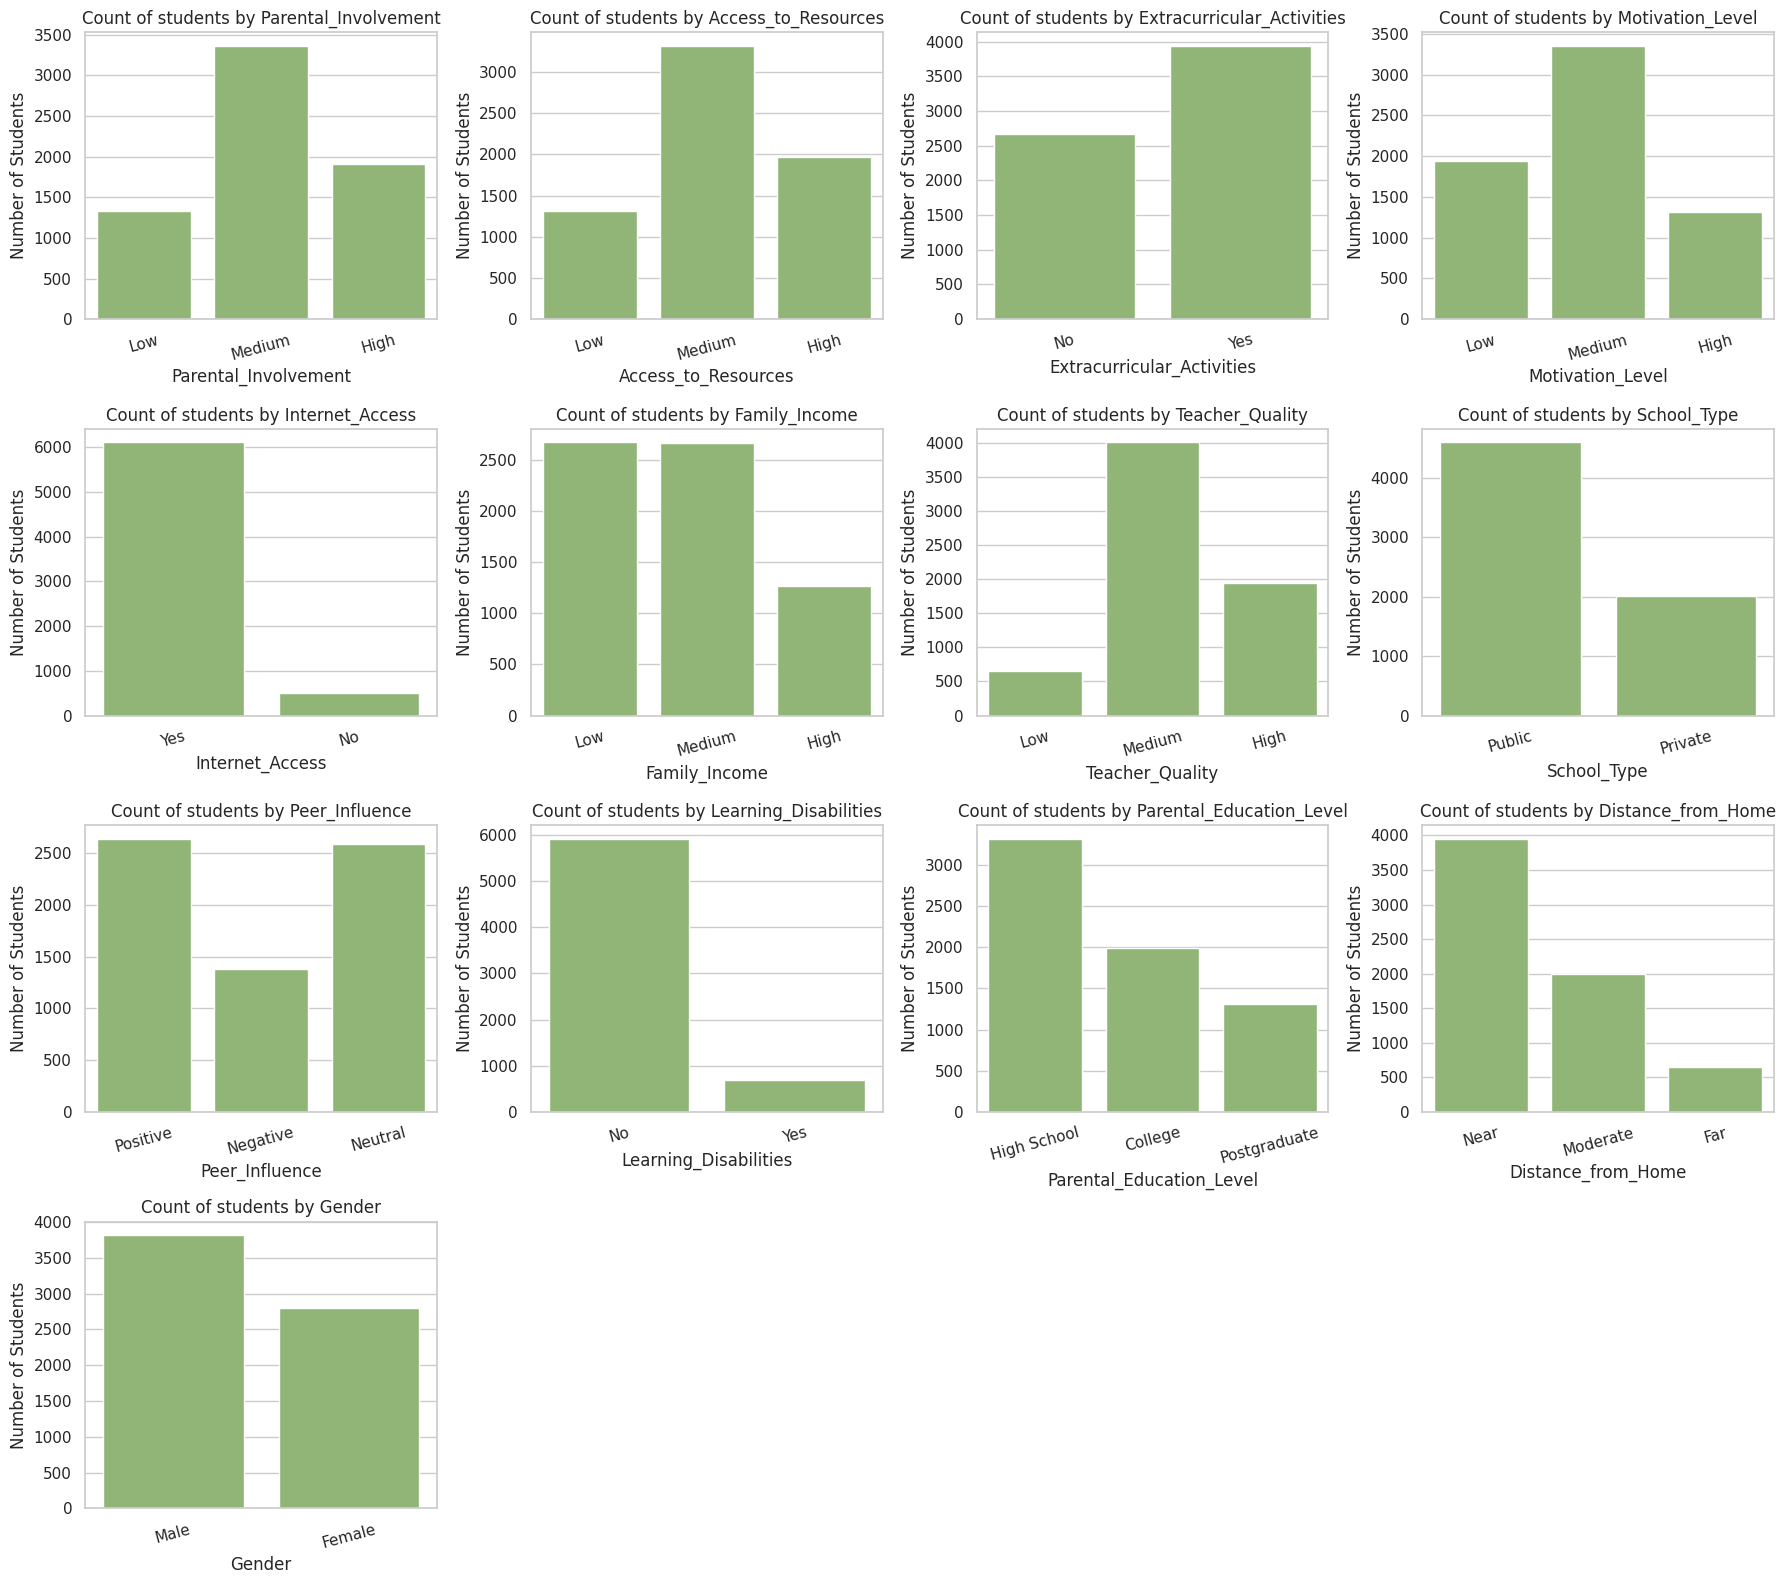

In [15]:
fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.ravel()
for ax, col in zip(axes, categorical_features):
    order = ['Low', 'Medium', 'High'] if set(df_eda[col].unique()) == {'Low', 'Medium', 'High'} else None
    sns.countplot(data=df_eda, x=col, order=order, color='#90be6d', ax=ax)
    ax.set_title(f'Count of students by {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Number of Students')
    ax.tick_params(axis='x', rotation=15)
for ax in axes[len(categorical_features):]:
    ax.axis('off')
save_fig('04_categorical_countplots.png')

**Interpretation.** Most categories are imbalanced in realistic ways: most students have Medium parental involvement and resources, almost all have Internet access (about 92 percent), most do not have a learning disability (about 90 percent), and about 70 percent attend public schools. The small groups (for example students with learning disabilities, or no Internet access) are the ones where we must be careful about reading too much into averages.

### 3.2 Bivariate and multivariate analysis

Attendance           0.582
Hours_Studied        0.447
Previous_Scores      0.174
Tutoring_Sessions    0.154
Physical_Activity    0.028
Sleep_Hours         -0.016
Name: Exam_Score, dtype: float64


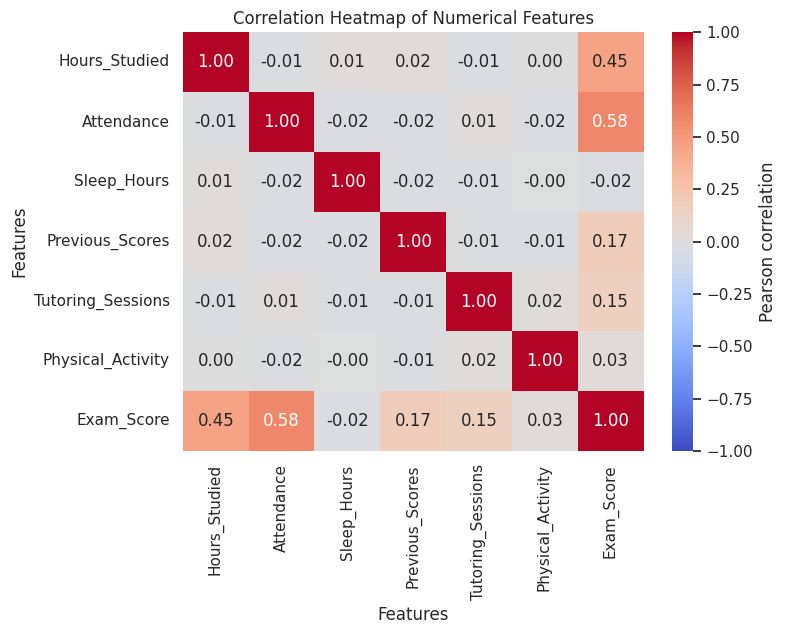

In [16]:
corr = df_eda[numeric_features + ['Exam_Score']].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={'label': 'Pearson correlation'})
ax.set_title('Correlation Heatmap of Numerical Features')
ax.set_xlabel('Features')
ax.set_ylabel('Features')
save_fig('05_correlation_heatmap.png')
print(corr['Exam_Score'].drop('Exam_Score').sort_values(ascending=False).round(3))

**Interpretation.** Correlation with `Exam_Score` ranks as: **Attendance (about 0.58)** > **Hours_Studied (about 0.45)** > **Previous_Scores (about 0.17)** > **Tutoring_Sessions (about 0.15)**; `Physical_Activity` (about 0.03) and `Sleep_Hours` (about -0.02) are close to zero. The predictors are almost uncorrelated with each other (no strong pairs), so multicollinearity is not a concern for Linear Regression. Correlation measures linear association only and does not prove cause and effect.

Access_to_Resources           1.89
Parental_Involvement          1.76
Parental_Education_Level      1.08
Learning_Disabilities         1.07
Peer_Influence                1.05
Distance_from_Home            1.04
Motivation_Level              0.97
Family_Income                 0.97
Teacher_Quality               0.91
Internet_Access               0.83
Extracurricular_Activities    0.50
School_Type                   0.08
Gender                        0.00

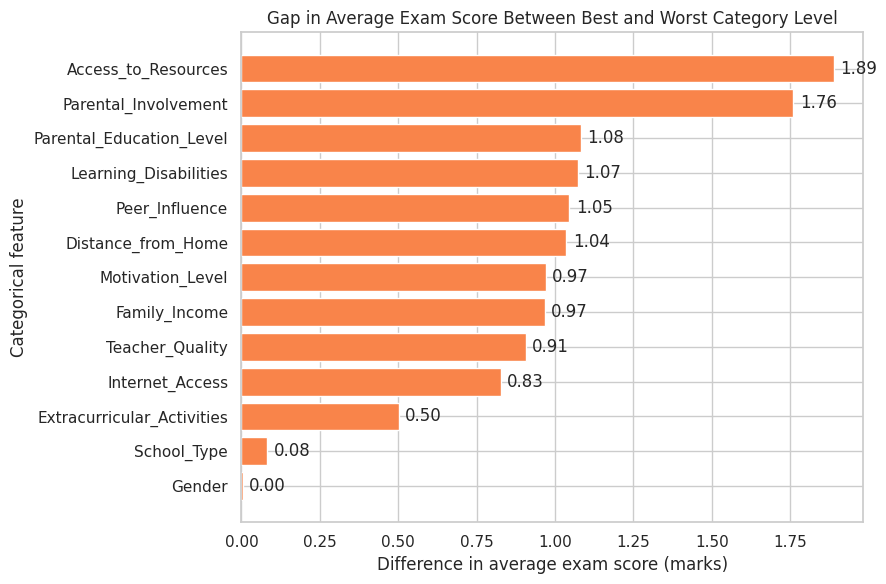

In [17]:
# How much does the average score change across the levels of each categorical feature?
spread = {}
for col in categorical_features:
    means = df_eda.groupby(col)['Exam_Score'].mean()
    spread[col] = means.max() - means.min()
spread = pd.Series(spread).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(spread.index, spread.values, color='#f9844a')
for i, v in enumerate(spread.values):
    ax.text(v + 0.02, i, f'{v:.2f}', va='center')
ax.set_title('Gap in Average Exam Score Between Best and Worst Category Level')
ax.set_xlabel('Difference in average exam score (marks)')
ax.set_ylabel('Categorical feature')
save_fig('06_categorical_score_gap.png')
spread.sort_values(ascending=False).round(2)

**Interpretation.** `Parental_Involvement` and `Access_to_Resources` show the largest gaps (about 1.7 to 1.9 marks between the best and worst level), followed by a group of factors that each show a gap of about 1 mark (`Parental_Education_Level`, `Learning_Disabilities`, `Peer_Influence`, `Distance_from_Home`, `Motivation_Level`, `Family_Income`). `Gender` (0.00) and `School_Type` (0.08) show almost no difference. Categorical effects are small in marks, compared with the effect of attendance and study hours (shown in the objectives below).

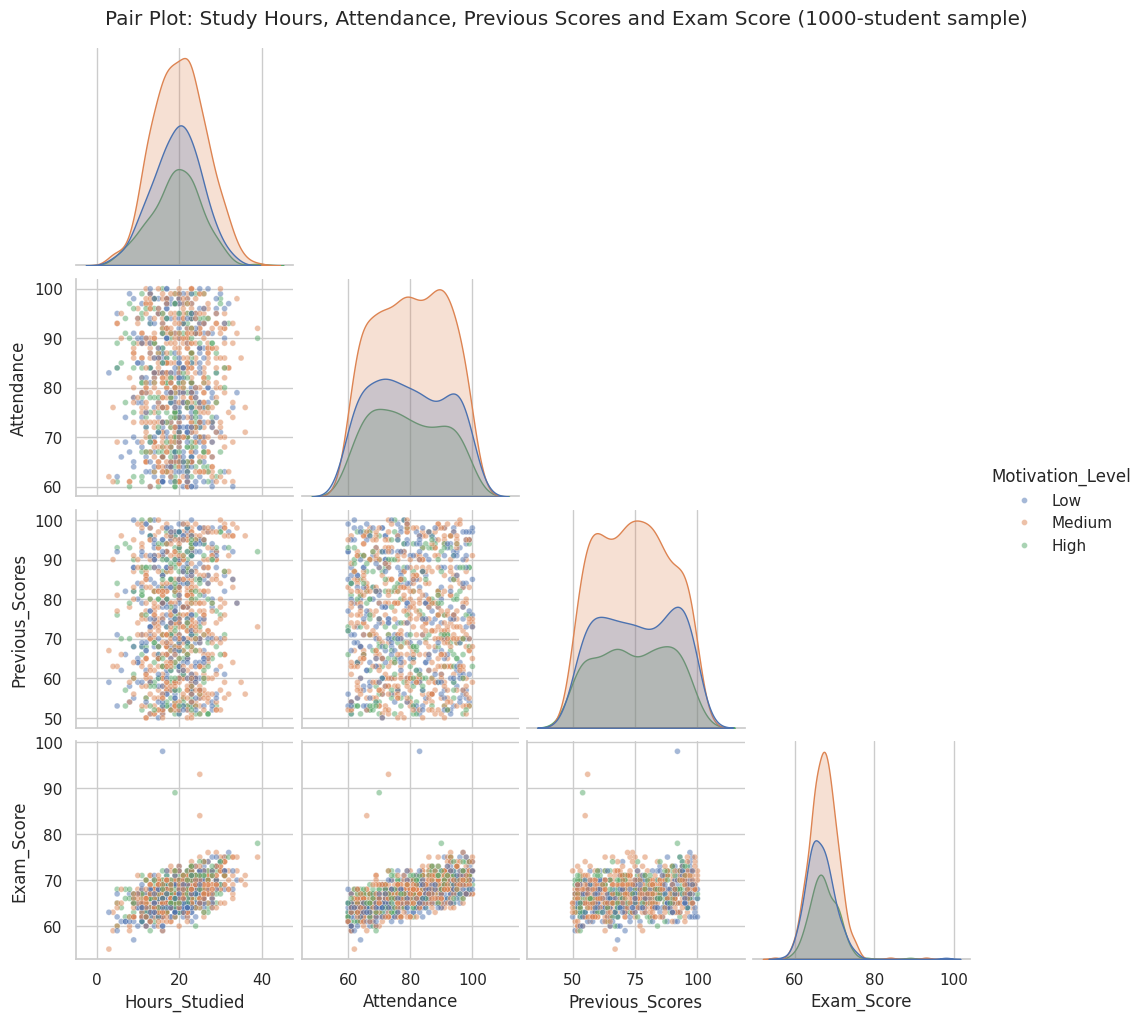

In [18]:
# Multivariate view: relationships between the strongest numeric features, coloured by motivation level
sample = df_eda.sample(1000, random_state=RANDOM_STATE)    # 1000-row sample only to keep the plot readable
pair = sns.pairplot(sample, vars=['Hours_Studied', 'Attendance', 'Previous_Scores', 'Exam_Score'],
                    hue='Motivation_Level', hue_order=['Low', 'Medium', 'High'], plot_kws={'alpha': 0.5, 's': 18}, corner=True)
pair.fig.suptitle('Pair Plot: Study Hours, Attendance, Previous Scores and Exam Score (1000-student sample)', y=1.02)
pair.fig.savefig(GRAPHS / '07_pairplot.png', dpi=110, bbox_inches='tight')
plt.show()

**Interpretation.** The bottom row shows `Exam_Score` rising with `Hours_Studied` and `Attendance` and only weakly with `Previous_Scores`. The predictors themselves show no pattern against each other (shapeless clouds), confirming they are independent. Colours overlap heavily, so motivation alone does not separate high and low scorers.

## Phase 3 (continued): Project objectives

Each objective has the same flow: *what and why*, analysis, graph, interpretation, conclusion.

### Objective 1: Study Hours Analysis
**What:** Examine the relationship between `Hours_Studied` and `Exam_Score`.
**Why important:** Study time is the factor students control most directly. Knowing how strongly it is associated with marks helps students plan their effort.

Pearson r = 0.447  (p-value = 2.92e-321)
Fitted line: Exam_Score = 61.47 + 0.288 x Hours_Studied


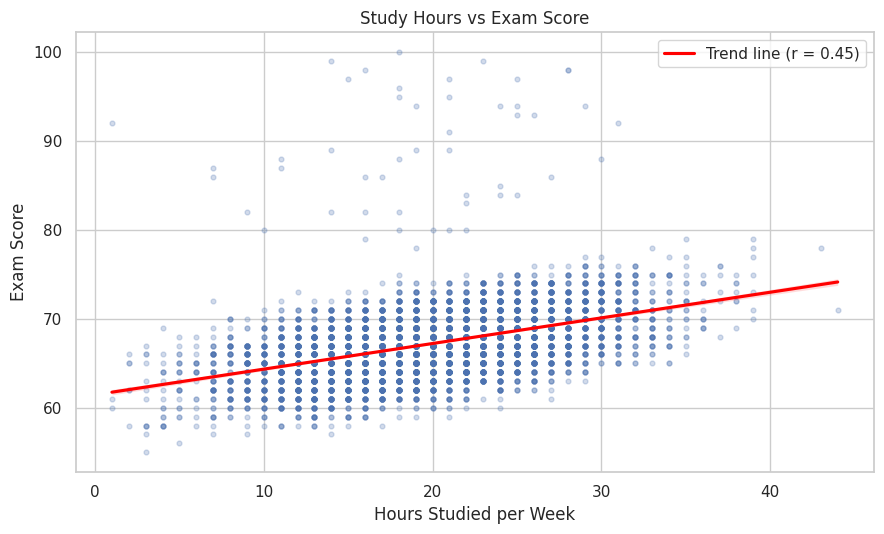

In [19]:
r, p = stats.pearsonr(df_eda['Hours_Studied'], df_eda['Exam_Score'])
slope, intercept = np.polyfit(df_eda['Hours_Studied'], df_eda['Exam_Score'], 1)
print(f'Pearson r = {r:.3f}  (p-value = {p:.2e})')
print(f'Fitted line: Exam_Score = {intercept:.2f} + {slope:.3f} x Hours_Studied')

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.regplot(data=df_eda, x='Hours_Studied', y='Exam_Score', scatter_kws={'alpha': 0.25, 's': 12},
            line_kws={'color': 'red', 'label': f'Trend line (r = {r:.2f})'}, ax=ax)
ax.set_title('Study Hours vs Exam Score')
ax.set_xlabel('Hours Studied per Week')
ax.set_ylabel('Exam Score')
ax.legend()
save_fig('08_obj1_hours_vs_score.png')

**Interpretation.** There is a clear positive, moderate relationship (r about 0.45). On the fitted line, each extra weekly study hour is associated with roughly 0.29 more marks, so about 10 extra hours goes with about 3 marks. The cloud around the line is wide, so study hours explain only part of the variation (r squared is about 20 percent).

**Conclusion.** Students who study more tend to score higher. This is an association; other factors (attendance, motivation) also matter and may overlap with study habits.

### Objective 2: Attendance Analysis
**What:** Analyse how `Attendance` is associated with `Exam_Score`.
**Why important:** Attendance is something institutions can monitor and act on early in a term.

Pearson r = 0.582  (p-value = 0.00e+00)
Fitted line: Exam_Score = 51.62 + 0.195 x Attendance
Average score at 60% attendance: 62.41 | at 100% attendance: 70.77


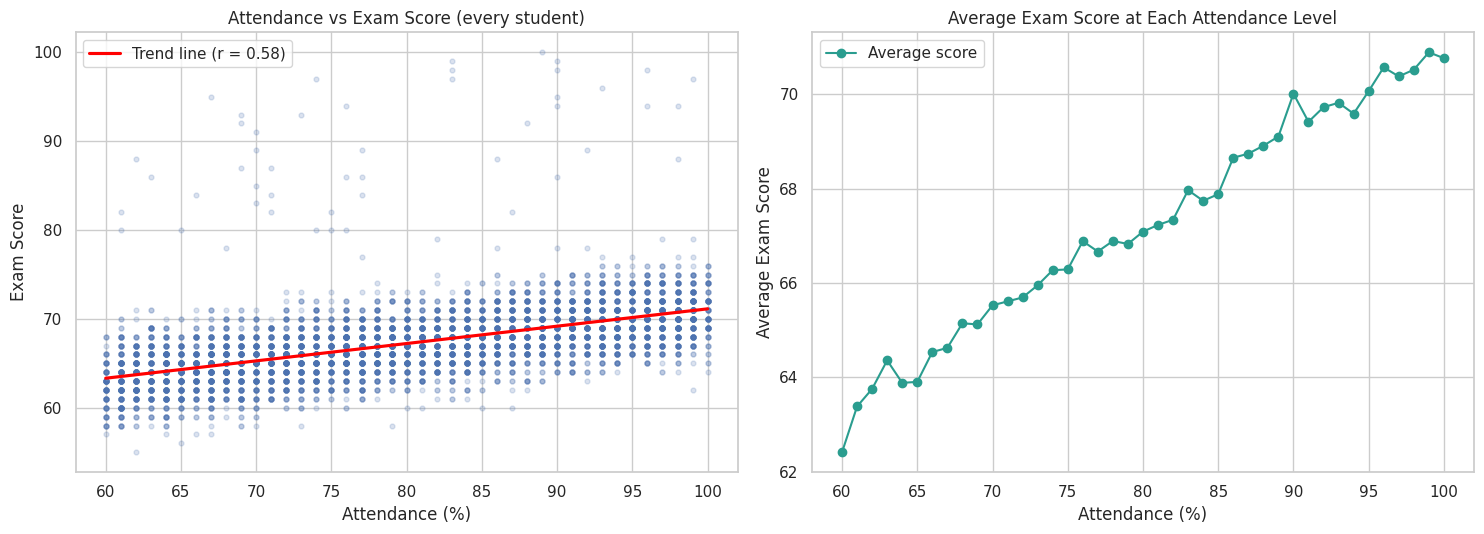

In [20]:
r, p = stats.pearsonr(df_eda['Attendance'], df_eda['Exam_Score'])
slope, intercept = np.polyfit(df_eda['Attendance'], df_eda['Exam_Score'], 1)
print(f'Pearson r = {r:.3f}  (p-value = {p:.2e})')
print(f'Fitted line: Exam_Score = {intercept:.2f} + {slope:.3f} x Attendance')

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.regplot(data=df_eda, x='Attendance', y='Exam_Score', scatter_kws={'alpha': 0.2, 's': 12},
            line_kws={'color': 'red', 'label': f'Trend line (r = {r:.2f})'}, ax=axes[0])
axes[0].set_title('Attendance vs Exam Score (every student)')
axes[0].set_xlabel('Attendance (%)')
axes[0].set_ylabel('Exam Score')
axes[0].legend()

avg_by_attendance = df_eda.groupby('Attendance')['Exam_Score'].mean()
axes[1].plot(avg_by_attendance.index, avg_by_attendance.values, marker='o', color='#2a9d8f', label='Average score')
axes[1].set_title('Average Exam Score at Each Attendance Level')
axes[1].set_xlabel('Attendance (%)')
axes[1].set_ylabel('Average Exam Score')
axes[1].legend()
save_fig('09_obj2_attendance_vs_score.png')
print('Average score at 60% attendance:', round(avg_by_attendance.loc[60], 2), '| at 100% attendance:', round(avg_by_attendance.loc[100], 2))

**Interpretation.** Attendance has the **strongest** relationship with exam score among all features (r about 0.58). The average score climbs steadily from about 62 at 60 percent attendance to about 71 at 100 percent attendance, with each extra percentage point linked to about 0.2 marks.

**Conclusion.** Higher attendance is strongly associated with higher scores. Attendance is also an easy-to-track warning signal for institutions, although attendance may partly reflect student engagement in general.

### Objective 3: Previous Academic Performance
**What:** Investigate the relationship between `Previous_Scores` and `Exam_Score`.
**Why important:** Past performance is the usual starting point for predicting future performance.

Pearson r = 0.174  (p-value = 2.65e-46)
Fitted line: Exam_Score = 63.71 + 0.047 x Previous_Scores


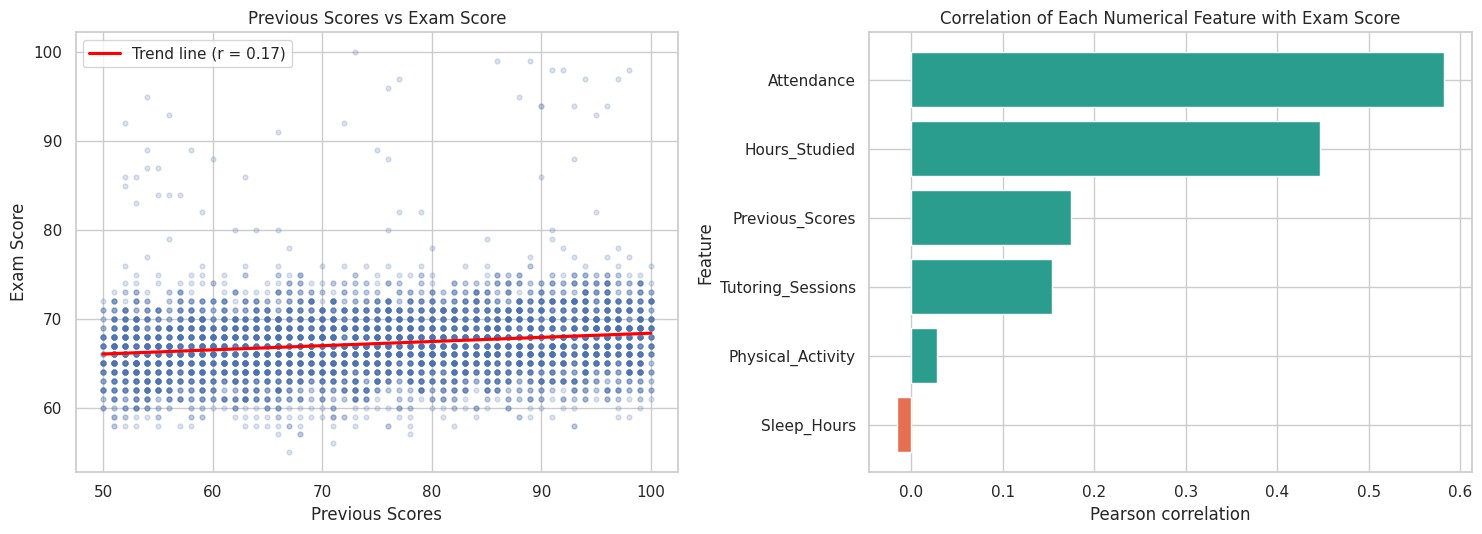

In [21]:
r, p = stats.pearsonr(df_eda['Previous_Scores'], df_eda['Exam_Score'])
slope, intercept = np.polyfit(df_eda['Previous_Scores'], df_eda['Exam_Score'], 1)
print(f'Pearson r = {r:.3f}  (p-value = {p:.2e})')
print(f'Fitted line: Exam_Score = {intercept:.2f} + {slope:.3f} x Previous_Scores')

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.regplot(data=df_eda, x='Previous_Scores', y='Exam_Score', scatter_kws={'alpha': 0.2, 's': 12},
            line_kws={'color': 'red', 'label': f'Trend line (r = {r:.2f})'}, ax=axes[0])
axes[0].set_title('Previous Scores vs Exam Score')
axes[0].set_xlabel('Previous Scores')
axes[0].set_ylabel('Exam Score')
axes[0].legend()

corr_with_target = df_eda[numeric_features].corrwith(df_eda['Exam_Score']).sort_values()
colors = ['#e76f51' if v < 0 else '#2a9d8f' for v in corr_with_target.values]
axes[1].barh(corr_with_target.index, corr_with_target.values, color=colors)
axes[1].set_title('Correlation of Each Numerical Feature with Exam Score')
axes[1].set_xlabel('Pearson correlation')
axes[1].set_ylabel('Feature')
save_fig('10_obj3_previous_scores.png')

**Interpretation.** Previous scores have a positive but **weak** relationship with the final score (r about 0.17); each extra previous mark is linked to only about 0.05 marks. This is lower than attendance and study hours. In many real datasets prior marks are the strongest predictor, so this is an interesting result about this particular dataset.

**Conclusion.** In this dataset, how a student studies and attends *now* is much more strongly associated with the exam score than how they performed before. Previous scores still help the prediction model a little.

### Objective 4: Sleep and Tutoring Analysis
**What:** Study how `Sleep_Hours` and `Tutoring_Sessions` are associated with exam performance.
**Why important:** Students are often told to sleep more or take extra coaching. We test whether the data supports it.

Sleep_Hours      : r = -0.016, p-value = 0.188
Tutoring_Sessions: r = 0.154, p-value = 3.12e-36

Average score by tutoring sessions:
                    mean  count
Tutoring_Sessions              
0                  66.49   1513
1                  66.98   2179
2                  67.57   1649
3                  67.89    836
4                  68.23    301
5+                 69.23    128


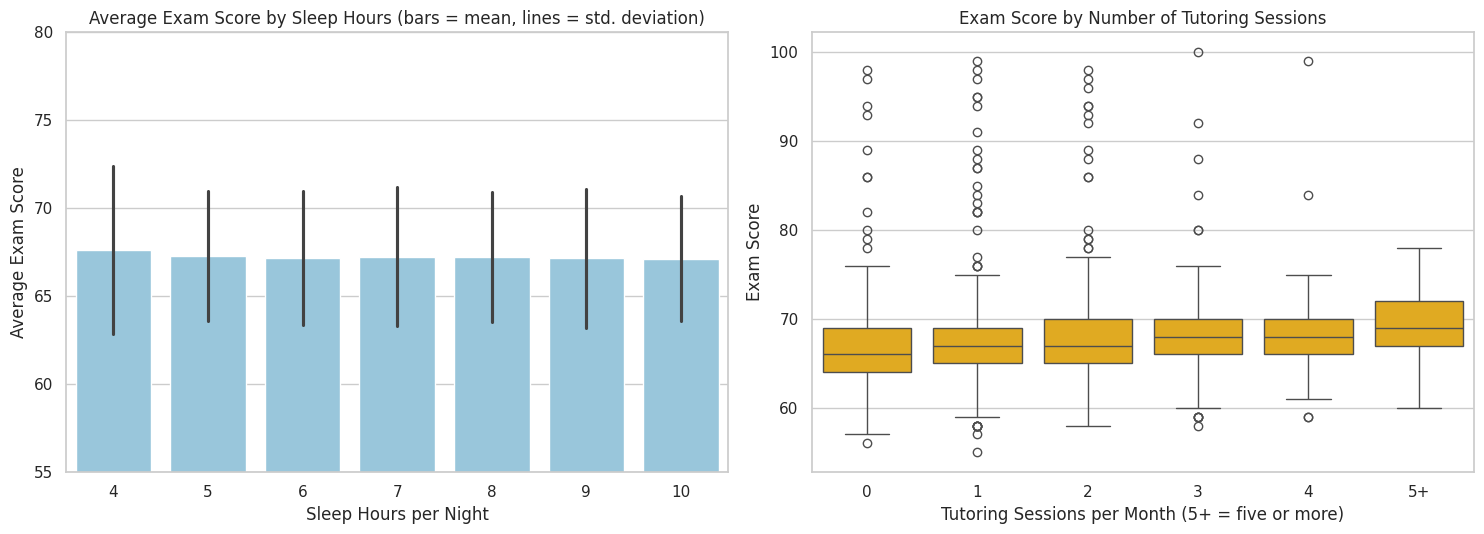

In [22]:
r_sleep, p_sleep = stats.pearsonr(df_eda['Sleep_Hours'], df_eda['Exam_Score'])
r_tut, p_tut = stats.pearsonr(df_eda['Tutoring_Sessions'], df_eda['Exam_Score'])
print(f'Sleep_Hours      : r = {r_sleep:.3f}, p-value = {p_sleep:.3f}')
print(f'Tutoring_Sessions: r = {r_tut:.3f}, p-value = {p_tut:.2e}')

# For the plot only, group 5 or more tutoring sessions together (very few students have 6, 7 or 8)
tutoring_grouped = df_eda['Tutoring_Sessions'].clip(upper=5).map(lambda v: '5+' if v >= 5 else str(v))
order = ['0', '1', '2', '3', '4', '5+']
print()
print('Average score by tutoring sessions:')
print(df_eda.groupby(tutoring_grouped)['Exam_Score'].agg(['mean', 'count']).loc[order].round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.barplot(data=df_eda, x='Sleep_Hours', y='Exam_Score', color='#8ecae6', errorbar='sd', ax=axes[0])
axes[0].set_title('Average Exam Score by Sleep Hours (bars = mean, lines = std. deviation)')
axes[0].set_xlabel('Sleep Hours per Night')
axes[0].set_ylabel('Average Exam Score')
axes[0].set_ylim(55, 80)

sns.boxplot(x=tutoring_grouped, y=df_eda['Exam_Score'], order=order, color='#ffb703', ax=axes[1])
axes[1].set_title('Exam Score by Number of Tutoring Sessions')
axes[1].set_xlabel('Tutoring Sessions per Month (5+ = five or more)')
axes[1].set_ylabel('Exam Score')
save_fig('11_obj4_sleep_tutoring.png')

**Interpretation.**
- **Sleep:** the average score is almost identical for every sleep duration from 4 to 10 hours (about 67 throughout) and the correlation is essentially zero (r about -0.02, not statistically significant). In this data, sleep duration shows **no meaningful association** with exam score.
- **Tutoring:** there is a small but consistent upward pattern. The average rises from about 66.5 with no tutoring to about 69.2 for five or more sessions (r about 0.15, statistically significant). Groups with 6 or more sessions are tiny (26 students in total), so we do not read much into them individually.

**Conclusion.** Tutoring is modestly associated with higher scores; sleep duration is not. We cannot claim tutoring *causes* the improvement (students who take tutoring may also differ in other ways), and the sleep finding applies only to the recorded sleep hours, not sleep quality.

### Objective 5: Overall Performance Factor Analysis (categorical factors)
**What:** Examine how `Motivation_Level`, `Parental_Involvement` and `Access_to_Resources` relate to `Exam_Score`.
**Why important:** These are factors that schools and families can influence through support programmes.

                 factor  mean_Low  mean_Medium  mean_High  High_minus_Low ANOVA_p_value
0      Motivation_Level     66.73        67.33      67.70            0.97      1.82e-12
1  Parental_Involvement     66.33        67.10      68.09            1.76      2.80e-38
2   Access_to_Resources     66.20        67.12      68.09            1.89      2.93e-43


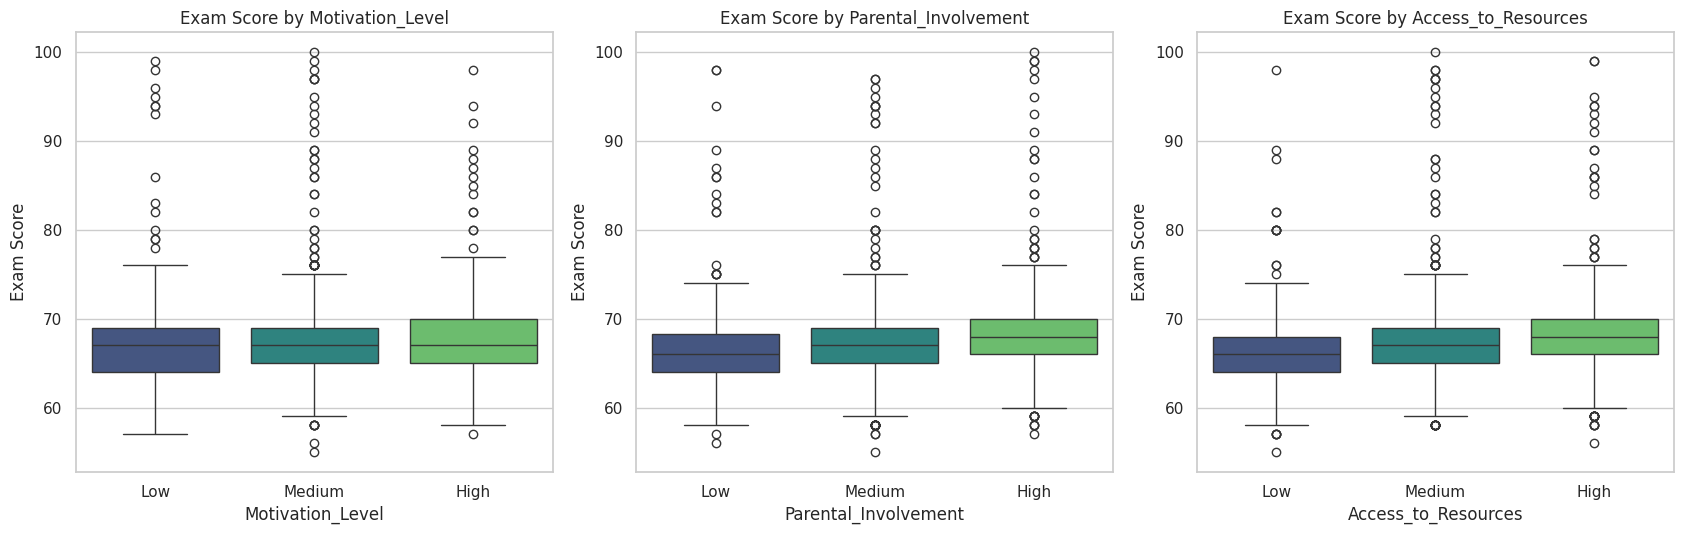

In [23]:
level_order = ['Low', 'Medium', 'High']
factors = ['Motivation_Level', 'Parental_Involvement', 'Access_to_Resources']

summary_rows = []
for col in factors:
    groups = [df_eda.loc[df_eda[col] == lvl, 'Exam_Score'] for lvl in level_order]
    f_stat, p_val = stats.f_oneway(*groups)
    row = {'factor': col}
    for lvl, g in zip(level_order, groups):
        row[f'mean_{lvl}'] = round(g.mean(), 2)
    row['High_minus_Low'] = round(row['mean_High'] - row['mean_Low'], 2)
    row['ANOVA_p_value'] = f'{p_val:.2e}'
    summary_rows.append(row)
display(pd.DataFrame(summary_rows))

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, col in zip(axes, factors):
    sns.boxplot(data=df_eda, x=col, y='Exam_Score', order=level_order, palette='viridis', ax=ax)
    ax.set_title(f'Exam Score by {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Exam Score')
save_fig('12_obj5_categorical_factors.png')

**Interpretation.** For all three factors, students at the **High** level score higher on average than those at the **Low** level, and the ANOVA tests say the differences are statistically significant. The gaps are small in marks: about **1.0** (Motivation), **1.8** (Parental Involvement) and **1.9** (Access to Resources). The boxes overlap heavily, so a "Low" student can easily outscore a "High" student.

**Conclusion.** Parental involvement and access to resources are associated with higher scores, but the size of the effect (about 2 marks) is smaller than the effect linked to attendance (about 8 marks across the attendance range) or study hours. Statistical significance here comes partly from the large sample size; the practical effect is modest.

## Phase 4: Feature engineering

We create three **category features** by grouping numeric columns into meaningful bands. They are created for **analysis and interpretation** (easy-to-read groups and a multivariate heatmap). For model training we keep the **original numeric columns**, because grouping a number into bands throws away detail, and the new columns would just repeat information already present (adding them would be redundant).

| New feature | Calculated from | Bands | Why |
|---|---|---|---|
| `Study_Category` | `Hours_Studied` | Low (up to 15 h), Moderate (16 to 24 h), High (25+ h) | Bands follow the quartiles (Q1 = 16, Q3 = 24), so we can compare light, typical and heavy study |
| `Attendance_Category` | `Attendance` | Low (60 to 69), Medium (70 to 84), High (85 to 100) | Matches common attendance cut-offs used by institutions |
| `Sleep_Category` | `Sleep_Hours` | Short (4 to 5 h), Adequate (6 to 8 h), Long (9 to 10 h) | Checks sleep in recognised ranges rather than every hour |

**Data-leakage check:** all three are derived only from input columns that a student knows *before* the exam. None uses `Exam_Score`.

In [24]:
df_fe = df_eda.copy()
df_fe['Study_Category'] = pd.cut(df_fe['Hours_Studied'], bins=[0, 15, 24, 100], labels=['Low (<=15 h)', 'Moderate (16-24 h)', 'High (25+ h)'])
df_fe['Attendance_Category'] = pd.cut(df_fe['Attendance'], bins=[0, 69, 84, 100], labels=['Low (60-69%)', 'Medium (70-84%)', 'High (85-100%)'])
df_fe['Sleep_Category'] = pd.cut(df_fe['Sleep_Hours'], bins=[0, 5, 8, 24], labels=['Short (4-5 h)', 'Adequate (6-8 h)', 'Long (9-10 h)'])

for col in ['Study_Category', 'Attendance_Category', 'Sleep_Category']:
    print(df_fe.groupby(col, observed=True)['Exam_Score'].agg(['count', 'mean']).round(2))
    print()

                    count   mean
Study_Category                  
Low (<=15 h)         1505  64.90
Moderate (16-24 h)   3640  67.23
High (25+ h)         1461  69.63

                     count   mean
Attendance_Category              
Low (60-69%)          1573  64.21
Medium (70-84%)       2523  66.68
High (85-100%)        2510  69.68

                  count   mean
Sleep_Category                
Short (4-5 h)      1004  67.40
Adequate (6-8 h)   4515  67.21
Long (9-10 h)      1087  67.15



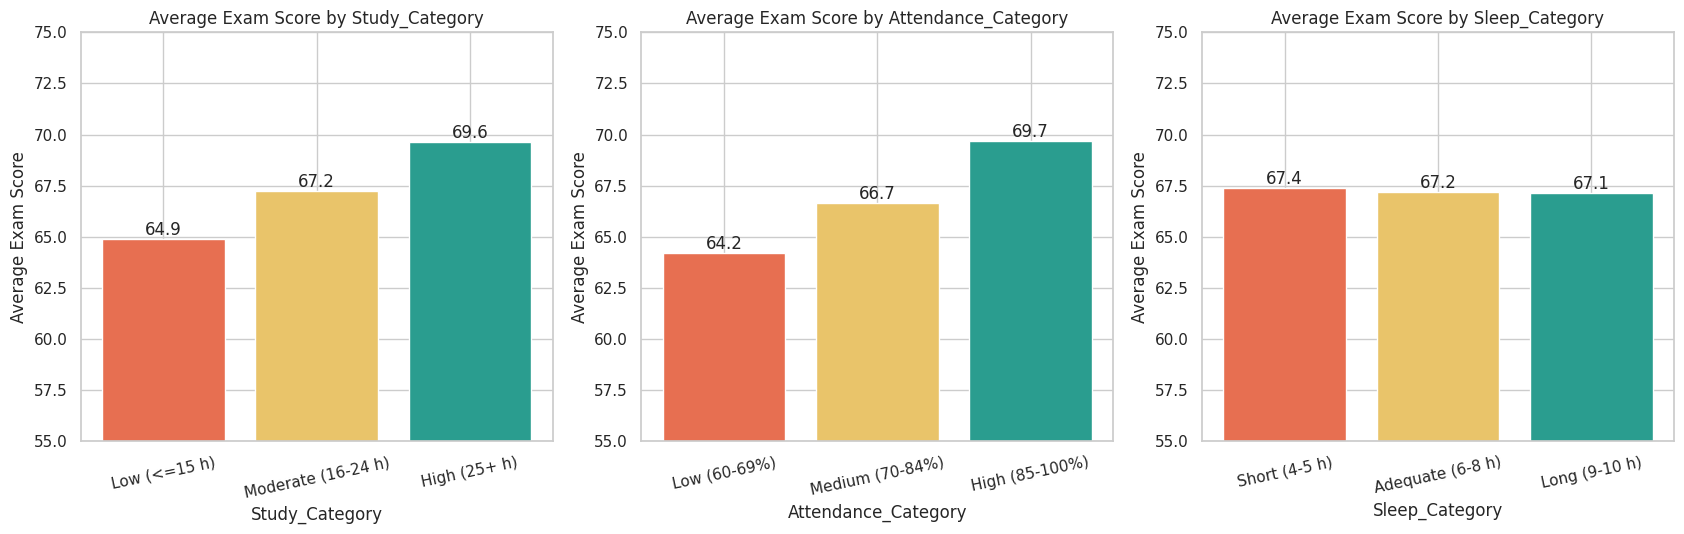

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, col in zip(axes, ['Study_Category', 'Attendance_Category', 'Sleep_Category']):
    means = df_fe.groupby(col, observed=True)['Exam_Score'].mean()
    bars = ax.bar(means.index.astype(str), means.values, color=['#e76f51', '#e9c46a', '#2a9d8f'])
    ax.bar_label(bars, fmt='%.1f')
    ax.set_title(f'Average Exam Score by {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Average Exam Score')
    ax.set_ylim(55, 75)
    ax.tick_params(axis='x', rotation=12)
save_fig('13_engineered_features.png')

Attendance_Category  Low (60-69%)  Medium (70-84%)  High (85-100%)
Study_Category                                                    
Low (<=15 h)                61.78            64.53           67.26
Moderate (16-24 h)          64.23            66.66           69.67
High (25+ h)                66.70            68.89           72.24

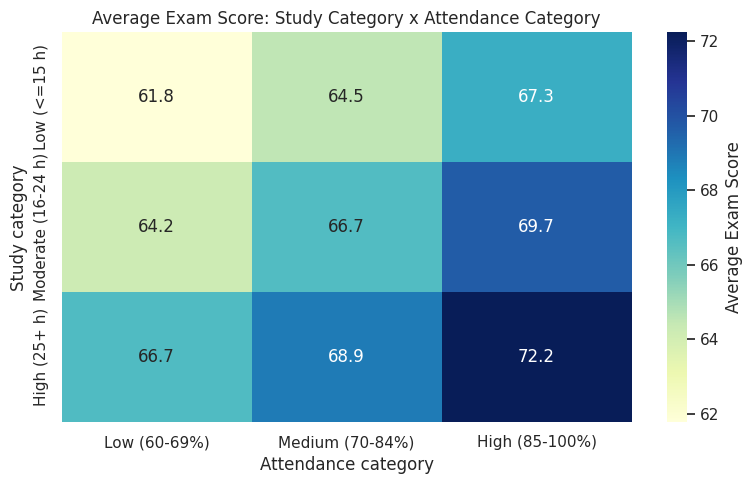

In [26]:
# Multivariate: average score for every combination of study category and attendance category
pivot = df_fe.pivot_table(values='Exam_Score', index='Study_Category', columns='Attendance_Category', aggfunc='mean', observed=True)
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='YlGnBu', ax=ax, cbar_kws={'label': 'Average Exam Score'})
ax.set_title('Average Exam Score: Study Category x Attendance Category')
ax.set_xlabel('Attendance category')
ax.set_ylabel('Study category')
save_fig('14_study_attendance_heatmap.png')
pivot.round(2)

**Interpretation.** Average score rises across the study bands and across the attendance bands, and the two effects add up: students with **High attendance and High study hours** average about 72 marks (72.2), while **Low attendance and Low study hours** average about 62 marks (61.8), a gap of roughly 10 marks. Sleep categories show virtually no difference, which agrees with Objective 4.

## Phase 5: Machine learning models

### 5.1 Prepare inputs and target, and split the data

- **Target (y):** `Exam_Score`.
- **Inputs (X):** all 19 original feature columns. The engineered category columns are *not* used (they only repeat information from the numeric columns). We use `df_clean`, which still has the missing values, because imputation must be learned from the training data only (otherwise information from the test set leaks into training).
- **Split:** 80 percent training, 20 percent testing with `random_state=42`. All four models use exactly the same split, so the comparison is fair.

In [27]:
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

X = df_clean.drop(columns='Exam_Score')
y = df_clean['Exam_Score']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('Training set:', X_train.shape, '| Test set:', X_test.shape)
print('Missing values in X_train:', X_train.isnull().sum().sum(), '(will be imputed inside the pipeline)')

Training set: (5284, 19) | Test set: (1322, 19)
Missing values in X_train: 179 (will be imputed inside the pipeline)


### 5.2 Preprocessing pipeline

A **pipeline** chains preprocessing and the model so that every step is learned from the training data only and then applied unchanged to new data (test data and, later, the Streamlit app).

| Column type | Steps |
|---|---|
| Numerical | `SimpleImputer(median)` then `StandardScaler` (scaling only for Linear Regression and KNN) |
| Categorical | `SimpleImputer(most_frequent)` then `OneHotEncoder(handle_unknown='ignore')` |

*Why scale only some models?* KNN works on distances, so a feature with large numbers (Attendance 60 to 100) would dominate a small one (Tutoring 0 to 8) unless we scale. Linear Regression is also fitted on scaled numbers so coefficients are comparable. Trees split on thresholds and do not need scaling.

In [28]:
numeric_features = X.select_dtypes(include='number').columns.tolist()
categorical_features = X.select_dtypes(exclude='number').columns.tolist()

def build_pipeline(model, scale_numeric):
    numeric_steps = [('impute', SimpleImputer(strategy='median'))]
    if scale_numeric:
        numeric_steps.append(('scale', StandardScaler()))
    preprocessing = ColumnTransformer([
        ('num', Pipeline(numeric_steps), numeric_features),
        ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_features),
    ])
    return Pipeline([('prep', preprocessing), ('model', model)])

def evaluate(name, fitted_pipeline):
    """Predict on the test set and return the four required metrics (plus train R2 to check overfitting)."""
    predictions = fitted_pipeline.predict(X_test)
    mse = mean_squared_error(y_test, predictions)
    return {'Model': name,
            'R2': r2_score(y_test, predictions),
            'MAE': mean_absolute_error(y_test, predictions),
            'MSE': mse,
            'RMSE': np.sqrt(mse),
            'Train_R2': r2_score(y_train, fitted_pipeline.predict(X_train))}, predictions

fitted_models, results, all_predictions = {}, [], {}
print('Numerical features:', numeric_features)
print('Categorical features:', categorical_features)

Numerical features: ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']
Categorical features: ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


### 5.3 Model 1: Linear Regression
**How it works (simple language):** it finds the best straight-line (weighted-sum) formula: `score = b0 + b1 x Hours + b2 x Attendance + ...`. Each weight says how many marks the score changes for a one-unit change in that feature, keeping the others fixed. It is fast and very easy to explain, but it can only capture straight-line relationships.

In [29]:
linear_pipeline = build_pipeline(LinearRegression(), scale_numeric=True)
linear_pipeline.fit(X_train, y_train)

metrics, preds = evaluate('Linear Regression', linear_pipeline)
fitted_models['Linear Regression'], all_predictions['Linear Regression'] = linear_pipeline, preds
results.append(metrics)
print({k: (round(v, 4) if not isinstance(v, str) else v) for k, v in metrics.items()})

{'Model': 'Linear Regression', 'R2': 0.825, 'MAE': 0.416, 'MSE': 2.3142, 'RMSE': np.float64(1.5213), 'Train_R2': 0.711}


### 5.4 Model 2: Decision Tree Regressor
**How it works:** it asks a series of yes/no questions (for example "Attendance above 85?") that split students into smaller and smaller groups. The prediction is the average score in the final group (leaf). Easy to visualise, but a deep tree memorises noise (overfits), so we limit its depth. The depth and minimum leaf size are chosen by 5-fold cross-validation on the **training set only**.

In [30]:
tree_search = GridSearchCV(
    build_pipeline(DecisionTreeRegressor(random_state=RANDOM_STATE), scale_numeric=False),
    param_grid={'model__max_depth': [3, 5, 7, 10, 15], 'model__min_samples_leaf': [5, 20]},
    cv=5, scoring='r2')
tree_search.fit(X_train, y_train)
print('Best settings found with cross-validation:', tree_search.best_params_)

tree_pipeline = tree_search.best_estimator_
metrics, preds = evaluate('Decision Tree', tree_pipeline)
fitted_models['Decision Tree'], all_predictions['Decision Tree'] = tree_pipeline, preds
results.append(metrics)
print({k: (round(v, 4) if not isinstance(v, str) else v) for k, v in metrics.items()})

Best settings found with cross-validation: {'model__max_depth': 15, 'model__min_samples_leaf': 20}
{'Model': 'Decision Tree', 'R2': 0.6023, 'MAE': 1.4468, 'MSE': 5.2596, 'RMSE': np.float64(2.2934), 'Train_R2': 0.6486}


### 5.5 Model 3: Random Forest Regressor
**How it works:** it builds many (here 200) different decision trees, each on a random sample of the rows and features, and **averages** their predictions. Averaging cancels out the errors of single trees, so it is usually more stable than one tree and handles non-linear patterns and interactions without scaling.

In [31]:
forest_pipeline = build_pipeline(
    RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1),
    scale_numeric=False)
forest_pipeline.fit(X_train, y_train)

metrics, preds = evaluate('Random Forest', forest_pipeline)
fitted_models['Random Forest'], all_predictions['Random Forest'] = forest_pipeline, preds
results.append(metrics)
print({k: (round(v, 4) if not isinstance(v, str) else v) for k, v in metrics.items()})

{'Model': 'Random Forest', 'R2': 0.7283, 'MAE': 1.0234, 'MSE': 3.5928, 'RMSE': np.float64(1.8955), 'Train_R2': 0.832}


### 5.6 Model 4: K-Nearest Neighbors Regressor
**How it works:** to predict a new student, it finds the K students in the training data who are most similar (smallest distance across all features) and **averages their scores**. It has no formula to learn, but it needs scaled inputs and can struggle when there are many features (many one-hot columns dilute the distance). K is chosen by cross-validation on the training set.

In [32]:
knn_search = GridSearchCV(
    build_pipeline(KNeighborsRegressor(), scale_numeric=True),
    param_grid={'model__n_neighbors': [5, 10, 15, 20, 30, 50]},
    cv=5, scoring='r2')
knn_search.fit(X_train, y_train)
print('Best number of neighbours found with cross-validation:', knn_search.best_params_)

knn_pipeline = knn_search.best_estimator_
metrics, preds = evaluate('KNN', knn_pipeline)
fitted_models['KNN'], all_predictions['KNN'] = knn_pipeline, preds
results.append(metrics)
print({k: (round(v, 4) if not isinstance(v, str) else v) for k, v in metrics.items()})

Best number of neighbours found with cross-validation: {'model__n_neighbors': 20}
{'Model': 'KNN', 'R2': 0.6482, 'MAE': 1.3469, 'MSE': 4.6518, 'RMSE': np.float64(2.1568), 'Train_R2': 0.6014}


## Phase 6: Model evaluation and comparison

### Meaning of the metrics (all computed on the 20 percent test set the models never saw)
- **R² score:** share of the variation in exam scores that the model explains. 1.0 is perfect, 0 means no better than always predicting the average. Higher is better.
- **MAE (Mean Absolute Error):** average size of the prediction error in marks, ignoring direction. Easy to interpret. Lower is better.
- **MSE (Mean Squared Error):** average of the squared errors. It punishes big mistakes more heavily, but its unit is "marks squared". Lower is better.
- **RMSE (Root MSE):** square root of MSE, so it is back in marks. It is larger than MAE when some errors are big. Lower is better.

In [33]:
comparison = pd.DataFrame(results).set_index('Model')
comparison_rounded = comparison.round(4)
comparison_rounded.to_csv(BASE / 'outputs' / 'model_comparison.csv')
comparison_rounded

                       R2     MAE     MSE    RMSE  Train_R2
Model                                                      
Linear Regression  0.8250  0.4160  2.3142  1.5213    0.7110
Decision Tree      0.6023  1.4468  5.2596  2.2934    0.6486
Random Forest      0.7283  1.0234  3.5928  1.8955    0.8320
KNN                0.6482  1.3469  4.6518  2.1568    0.6014

In [34]:
# Best model = highest test R2 (lowest RMSE breaks a tie). Nothing is assumed in advance.
best_name = comparison.sort_values(['R2', 'RMSE'], ascending=[False, True]).index[0]
best_pipeline = fitted_models[best_name]
print('Best model on the test set:', best_name)
print(comparison.loc[best_name, ['R2', 'MAE', 'MSE', 'RMSE']].round(4).to_string())

Best model on the test set: Linear Regression
R2      0.8250
MAE     0.4160
MSE     2.3142
RMSE    1.5213


**Reading the table.** Linear Regression is clearly the best on every metric: R² of about 0.825, an average error (MAE) of only about 0.42 marks and RMSE of about 1.52 marks. Random Forest is second (R² about 0.73, MAE about 1.02), then KNN (R² about 0.65) and Decision Tree (R² about 0.60).

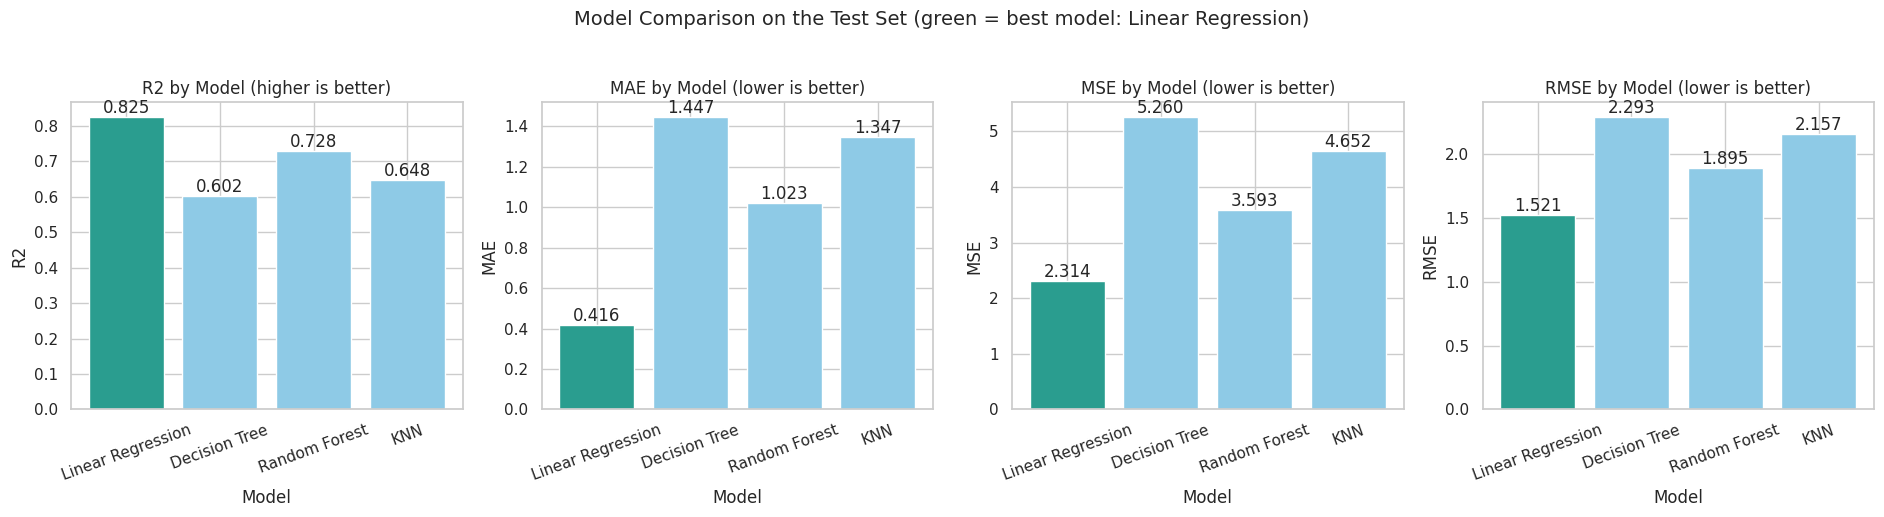

In [35]:
fig, axes = plt.subplots(1, 4, figsize=(19, 5))
palette = ['#2a9d8f' if m == best_name else '#8ecae6' for m in comparison.index]
for ax, metric, better in zip(axes, ['R2', 'MAE', 'MSE', 'RMSE'], ['higher', 'lower', 'lower', 'lower']):
    bars = ax.bar(comparison.index, comparison[metric], color=palette)
    ax.bar_label(bars, fmt='%.3f')
    ax.set_title(f'{metric} by Model ({better} is better)')
    ax.set_xlabel('Model')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=20)
fig.suptitle(f'Model Comparison on the Test Set (green = best model: {best_name})', y=1.03, fontsize=14)
save_fig('15_model_comparison.png')

### Overfitting check: training R² versus test R²

In [36]:
overfit = comparison[['Train_R2', 'R2']].rename(columns={'R2': 'Test_R2'})
overfit['Gap (Train - Test)'] = overfit['Train_R2'] - overfit['Test_R2']
overfit.round(4)

                   Train_R2  Test_R2  Gap (Train - Test)
Model                                                   
Linear Regression    0.7110   0.8250             -0.1140
Decision Tree        0.6486   0.6023              0.0463
Random Forest        0.8320   0.7283              0.1036
KNN                  0.6014   0.6482             -0.0469

**Why does the simplest model win?** The relationships found in the EDA are mostly straight-line and additive (more attendance gives more marks, more study hours gives more marks, and the factors add up). Linear Regression is built exactly for that. A single Decision Tree and KNN approximate a straight line with steps or neighbourhood averages and need far more data to match it. Random Forest smooths the steps by averaging 200 trees, which is why it beats the single tree, but it still does not reach the straight-line fit. This is a statement about *this dataset*; with messier real-world data, tree-based models often win.

**Overfitting check.** Random Forest fits the training data better than test data (R² 0.83 versus 0.73), the usual sign of mild overfitting. Decision Tree has a small gap (0.65 versus 0.60). For Linear Regression and KNN the test R² is actually *higher* than the training R². That is not a sign of a better model: it happens because the test set happened to contain few of the extreme, hard-to-explain scores (explained in the error analysis below).

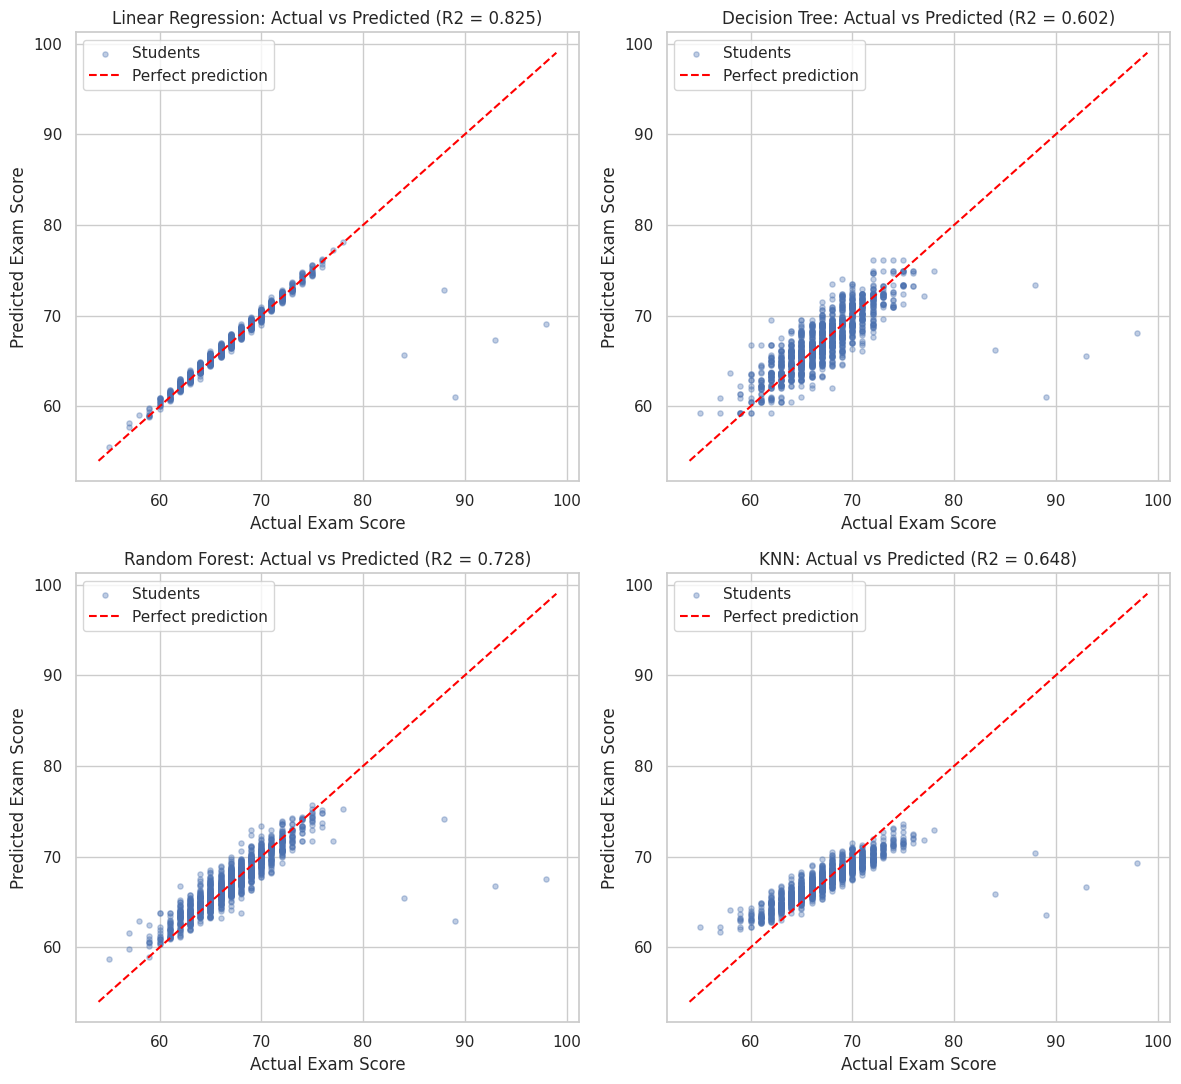

In [37]:
# Actual versus predicted for all four models (red dashed line = perfect prediction)
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
for ax, name in zip(axes.ravel(), comparison.index):
    ax.scatter(y_test, all_predictions[name], alpha=0.35, s=14, label='Students')
    lims = [y_test.min() - 1, y_test.max() + 1]
    ax.plot(lims, lims, color='red', linestyle='--', label='Perfect prediction')
    ax.set_title(f'{name}: Actual vs Predicted (R2 = {comparison.loc[name, "R2"]:.3f})')
    ax.set_xlabel('Actual Exam Score')
    ax.set_ylabel('Predicted Exam Score')
    ax.legend()
save_fig('16_actual_vs_predicted_all_models.png')

Mean residual: -0.098 | Std of residuals: 1.519
Share of test predictions within +/- 1 mark: 98.7 %
Share of test predictions within +/- 2 marks: 99.6 %
Largest absolute error: 28.96 marks


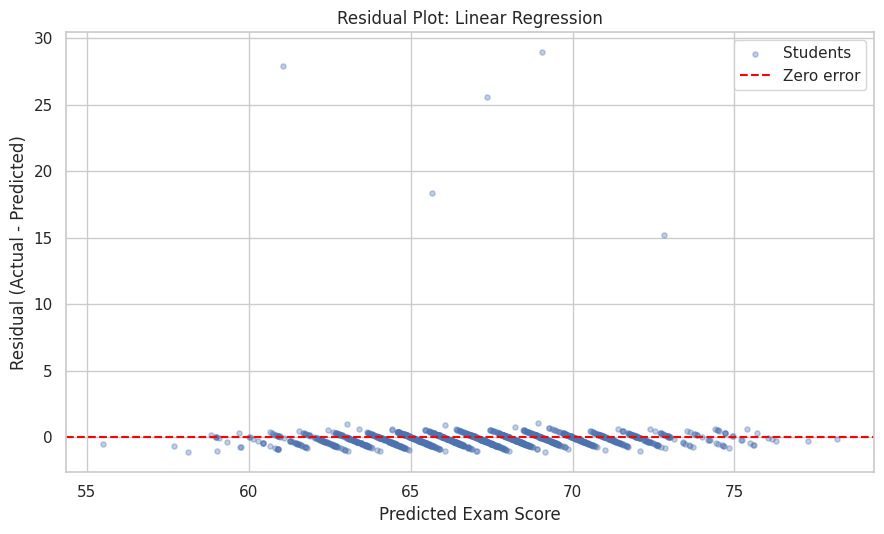

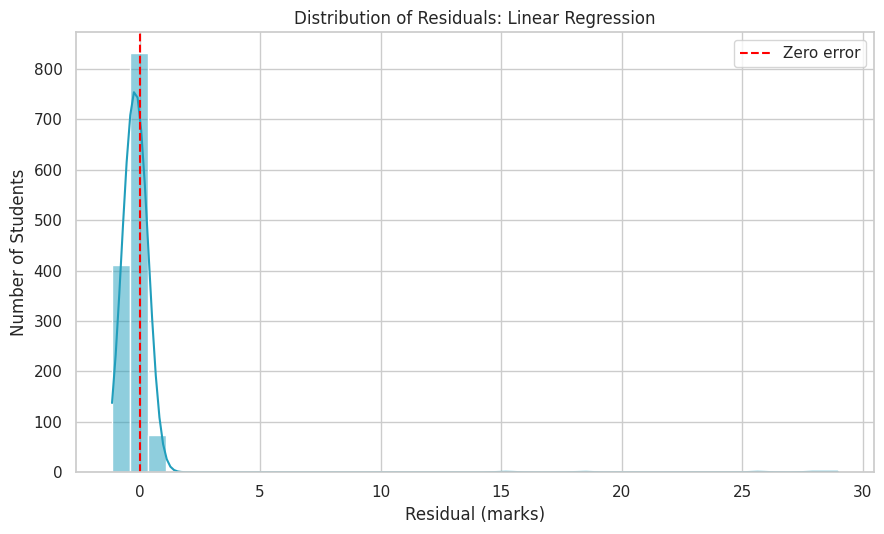

In [38]:
# Residuals of the best model (residual = actual - predicted)
best_predictions = all_predictions[best_name]
residuals = y_test - best_predictions

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(best_predictions, residuals, alpha=0.35, s=14, label='Students')
ax.axhline(0, color='red', linestyle='--', label='Zero error')
ax.set_title(f'Residual Plot: {best_name}')
ax.set_xlabel('Predicted Exam Score')
ax.set_ylabel('Residual (Actual - Predicted)')
ax.legend()
save_fig('17_residual_plot.png')

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.histplot(residuals, bins=40, kde=True, color='#219ebc', ax=ax)
ax.axvline(0, color='red', linestyle='--', label='Zero error')
ax.set_title(f'Distribution of Residuals: {best_name}')
ax.set_xlabel('Residual (marks)')
ax.set_ylabel('Number of Students')
ax.legend()
save_fig('18_residual_distribution.png')
print('Mean residual:', round(residuals.mean(), 3), '| Std of residuals:', round(residuals.std(), 3))
print('Share of test predictions within +/- 1 mark:', round((residuals.abs() <= 1).mean() * 100, 1), '%')
print('Share of test predictions within +/- 2 marks:', round((residuals.abs() <= 2).mean() * 100, 1), '%')
print('Largest absolute error:', round(residuals.abs().max(), 2), 'marks')

**Interpretation.** In the actual-vs-predicted plots, Linear Regression's points lie almost exactly on the red diagonal, apart from a few students whose real scores are much higher than predicted. Random Forest, Decision Tree and KNN show a wider band around the diagonal. For the best model, the residuals are centred on zero and **98.7 percent of test predictions are within 1 mark**; the residual histogram is a very narrow peak with a small number of large positive errors (students who scored far above what their inputs suggested). The mean residual is slightly negative (-0.10) because the few large errors are all in one direction. The model rarely over-predicts and, for a small group of students, under-predicts by a lot.

### Feature importance

Linear Regression: 10 largest coefficients
Attendance                   2.284
Hours_Studied                1.744
Access_to_Resources_Low     -1.050
Access_to_Resources_High     1.044
Parental_Involvement_High    1.034
Parental_Involvement_Low    -0.985
Previous_Scores              0.703
Tutoring_Sessions            0.594
Motivation_Level_High        0.547
Motivation_Level_Low        -0.533

Random Forest: top 8 importances
Attendance                   0.432
Hours_Studied                0.255
Previous_Scores              0.075
Tutoring_Sessions            0.028
Parental_Involvement_High    0.021
Access_to_Resources_High     0.020
Sleep_Hours                  0.016
Physical_Activity            0.016


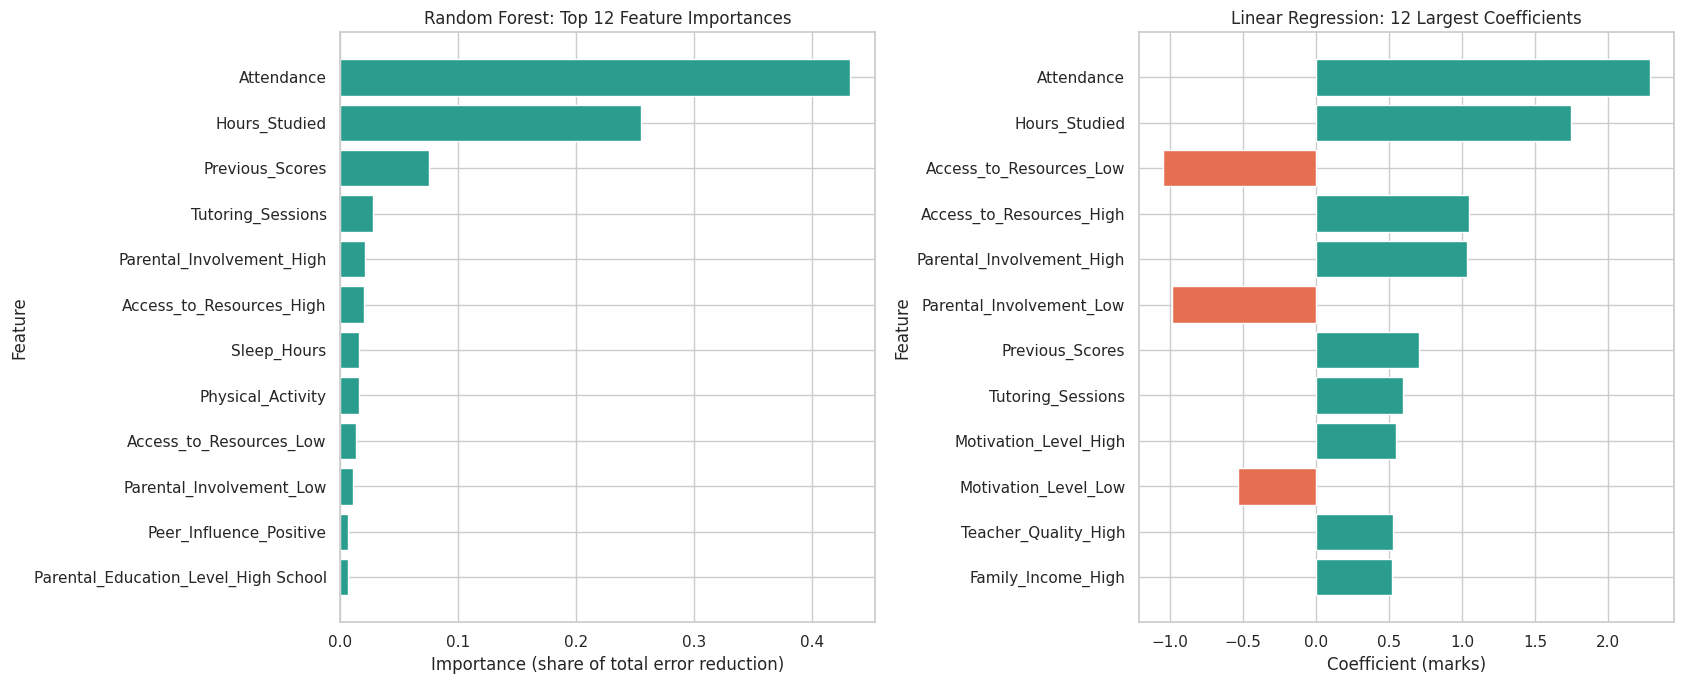

In [39]:
def clean_names(pipeline):
    names = pipeline.named_steps['prep'].get_feature_names_out()
    return [n.replace('num__', '').replace('cat__', '') for n in names]

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

# Random Forest: impurity-based importance (how much each feature reduces error across all trees)
forest_importance = pd.Series(fitted_models['Random Forest'].named_steps['model'].feature_importances_,
                              index=clean_names(fitted_models['Random Forest'])).sort_values().tail(12)
axes[0].barh(forest_importance.index, forest_importance.values, color='#2a9d8f')
axes[0].set_title('Random Forest: Top 12 Feature Importances')
axes[0].set_xlabel('Importance (share of total error reduction)')
axes[0].set_ylabel('Feature')

# Linear Regression: coefficients (numeric features are standardised, so they are comparable with each other)
linear_coef = pd.Series(fitted_models['Linear Regression'].named_steps['model'].coef_,
                        index=clean_names(fitted_models['Linear Regression']))
top_coef = linear_coef.reindex(linear_coef.abs().sort_values().tail(12).index)
axes[1].barh(top_coef.index, top_coef.values, color=['#e76f51' if v < 0 else '#2a9d8f' for v in top_coef.values])
axes[1].set_title('Linear Regression: 12 Largest Coefficients')
axes[1].set_xlabel('Coefficient (marks)')
axes[1].set_ylabel('Feature')
save_fig('19_feature_importance.png')

print('Linear Regression: 10 largest coefficients')
print(linear_coef.reindex(linear_coef.abs().sort_values(ascending=False).index).head(10).round(3).to_string())
print()
print('Random Forest: top 8 importances')
print(forest_importance.sort_values(ascending=False).head(8).round(3).to_string())

**Note on reading the coefficients.** In Linear Regression the numeric inputs are standardised, so a numeric coefficient is "marks change for a one standard-deviation increase". One-hot category coefficients are "marks difference compared with the category left out". Categories left out are absorbed in the intercept, so only compare numeric-with-numeric and category-with-category.

**Interpretation.** Both models agree on the order of the top factors: **Attendance** first and **Hours_Studied** second (in Random Forest, 43 percent and 26 percent of the total importance), then `Previous_Scores` and `Tutoring_Sessions`. In Linear Regression, the standardised coefficients say a one standard-deviation increase in attendance (about 11.5 points) goes with about +2.3 marks, and in study hours (about 6 hours) about +1.7 marks. Parental involvement, access to resources and motivation matter at the level of about 0.5 to 1 mark between their high and low levels. `Sleep_Hours` and `Physical_Activity` carry almost no importance.

### Robustness check 1: error analysis (where does the best model go wrong?)
Most predictions are very accurate, yet R² is only 0.83, and the largest error is nearly 29 marks. We look at the size of errors across the **whole cleaned dataset** (training and test) to understand why.

In [40]:
all_residuals = y - best_pipeline.predict(X)
bands = pd.cut(all_residuals.abs(), bins=[-0.01, 1, 2, 5, 100], labels=['within 1 mark', '1 to 2 marks', '2 to 5 marks', 'more than 5 marks'])
print('Absolute prediction error of the best model, all', len(y), 'students:')
print(bands.value_counts().reindex(['within 1 mark', '1 to 2 marks', '2 to 5 marks', 'more than 5 marks']).to_frame('students'))
print()

unexplained = all_residuals.abs() > 10
print('Students with error above 10 marks:', unexplained.sum(), f'({unexplained.mean() * 100:.2f}% of all students)')
print('Their actual exam scores range from', y[unexplained].min(), 'to', y[unexplained].max(), '(dataset average is', round(y.mean(), 1), ')')
print('Their predicted scores range from', best_pipeline.predict(X[unexplained]).min().round(1), 'to', best_pipeline.predict(X[unexplained]).max().round(1))

mask = ~(y_test - best_predictions).abs().gt(10)
print()
print('Test R2 with all test students           :', round(r2_score(y_test, best_predictions), 4))
print('Test R2 without the', (~mask).sum(), 'test students having error > 10:', round(r2_score(y_test[mask], best_predictions[mask]), 4))
print('(For comparison: these students are', (~mask).sum(), 'of', len(y_test), 'in the test set but', int((unexplained.sum() - (~mask).sum())), 'of', len(y_train), 'in the training set)')

Absolute prediction error of the best model, all 6606 students:
                   students
Exam_Score                 
within 1 mark          6516
1 to 2 marks             41
2 to 5 marks              0
more than 5 marks        49

Students with error above 10 marks: 49 (0.74% of all students)
Their actual exam scores range from 78 to 100 (dataset average is 67.2 )
Their predicted scores range from 60.1 to 75.8

Test R2 with all test students           : 0.825
Test R2 without the 5 test students having error > 10: 0.9852
(For comparison: these students are 5 of 1322 in the test set but 44 of 5284 in the training set)


### Robustness check 2: 5-fold cross-validation for all four models
A single train-test split can be lucky or unlucky (as the extreme scores above show). Cross-validation repeats the evaluation on 5 different parts of the **training set**, giving a steadier ranking. The models keep the settings chosen earlier.

In [41]:
cv_rows = []
for name, pipeline in fitted_models.items():
    scores = cross_val_score(pipeline, X_train, y_train, cv=5, scoring='r2')
    cv_rows.append({'Model': name, 'CV_R2_mean': scores.mean(), 'CV_R2_std': scores.std(), 'Test_R2': comparison.loc[name, 'R2']})
cv_table = pd.DataFrame(cv_rows).set_index('Model').round(4)
cv_table.to_csv(BASE / 'outputs' / 'cross_validation_r2.csv')
cv_table

                   CV_R2_mean  CV_R2_std  Test_R2
Model                                            
Linear Regression      0.7166     0.0910   0.8250
Decision Tree          0.5314     0.0679   0.6023
Random Forest          0.6342     0.0798   0.7283
KNN                    0.5574     0.0645   0.6482

**Interpretation of the error analysis.** For 6,516 of the 6,606 students (98.6 percent) the best model predicts within 1 mark, 41 more are within 2 marks, **none** are between 2 and 5 marks, and 49 students (0.74 percent) are off by more than 5 marks (all by more than 10 marks). Those 49 students all scored between 78 and 100 while the model expected about 60 to 76. Their scores are not explained by any of the 19 recorded features. This explains the apparently modest R²: if the 5 such students in the test set are set aside, R² rises from 0.825 to **0.985**. It also explains why the test R² is higher than the training R²: only 5 of these students fell in the test set, versus 44 in the training set.

**Interpretation of the cross-validation.** Under 5-fold cross-validation the order of the models is the same as on the test set: Linear Regression (mean R² about 0.72), Random Forest (about 0.63), KNN (about 0.56) and Decision Tree (about 0.53). The cross-validation R² values are lower than the test values for all models because the folds contain more of the extreme students. So the *ranking* is reliable. The absolute R² depends on how many unexplained extreme scores a sample contains: expect roughly 0.7 to 0.8 for Linear Regression, not a fixed 0.825.

**Selection.** The best-fit model, chosen only from the test-set results, is **Linear Regression**.

## Phase 7: Save the best model for the Streamlit app

In [42]:
# Save the complete pipeline (preprocessing + model) so the app applies exactly the same steps
joblib.dump(best_pipeline, MODELS / 'best_model.pkl')

import sklearn
metadata = {
    'best_model': best_name,
    'test_metrics': {k: round(float(comparison.loc[best_name, k]), 4) for k in ['R2', 'MAE', 'MSE', 'RMSE']},
    'feature_order': X.columns.tolist(),
    'numeric_ranges': {c: [int(df_clean[c].min()), int(df_clean[c].max())] for c in numeric_features},
    'categorical_options': {c: sorted(df_clean[c].dropna().unique().tolist()) for c in categorical_features},
    'sklearn_version': sklearn.__version__,
    'random_state': RANDOM_STATE,
}
with open(MODELS / 'model_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)

# Prove the saved file works: reload it and compare with the in-memory model on the test set
loaded_model = joblib.load(MODELS / 'best_model.pkl')
same = np.allclose(loaded_model.predict(X_test), best_pipeline.predict(X_test))
print('Saved:', MODELS / 'best_model.pkl')
print('Reloaded model gives identical predictions on the test set:', same)

# Example prediction for one new student (the same input format the app uses)
example_student = pd.DataFrame([{
    'Hours_Studied': 20, 'Attendance': 85, 'Parental_Involvement': 'Medium', 'Access_to_Resources': 'Medium',
    'Extracurricular_Activities': 'Yes', 'Sleep_Hours': 7, 'Previous_Scores': 75, 'Motivation_Level': 'Medium',
    'Internet_Access': 'Yes', 'Tutoring_Sessions': 1, 'Family_Income': 'Medium', 'Teacher_Quality': 'Medium',
    'School_Type': 'Public', 'Peer_Influence': 'Neutral', 'Physical_Activity': 3, 'Learning_Disabilities': 'No',
    'Parental_Education_Level': 'College', 'Distance_from_Home': 'Near', 'Gender': 'Male'}])[X.columns]
print('Example predicted exam score:', round(float(loaded_model.predict(example_student)[0]), 2))

Saved: ../models/best_model.pkl
Reloaded model gives identical predictions on the test set: True
Example predicted exam score: 68.54


## Phase 9: Summary dashboard (accuracy, errors and key factors on one page)

One page that combines the most important results: model accuracy (R² as a percentage), prediction error, how many predictions are close to the real score, predicted versus actual, residuals, important factors and the main relationships found in the EDA. It is saved as `outputs/graphs/20_dashboard.png`.

**Accuracy for regression.** A regression model cannot be simply right or wrong, so we use R² (as a percentage of variation explained) and the percentage of predictions that fall within 1, 2 or 5 marks of the real score.

In [43]:
# Share of test predictions within a tolerance of the real score (a simple "accuracy" for regression)
tolerance = pd.DataFrame({
    f'within {t} mark' + ('s' if t > 1 else ''): {m: (y_test - p).abs().le(t).mean() * 100 for m, p in all_predictions.items()}
    for t in (1, 2, 5)})
tolerance.round(1).to_csv(BASE / 'outputs' / 'tolerance_accuracy.csv')
print('Percentage of test students predicted within the given number of marks:')
print(tolerance.round(1))

Percentage of test students predicted within the given number of marks:
                   within 1 mark  within 2 marks  within 5 marks
Linear Regression           98.7            99.6            99.6
Decision Tree               46.7            75.7            99.2
Random Forest               61.6            90.8            99.5
KNN                         48.0            79.9            99.2


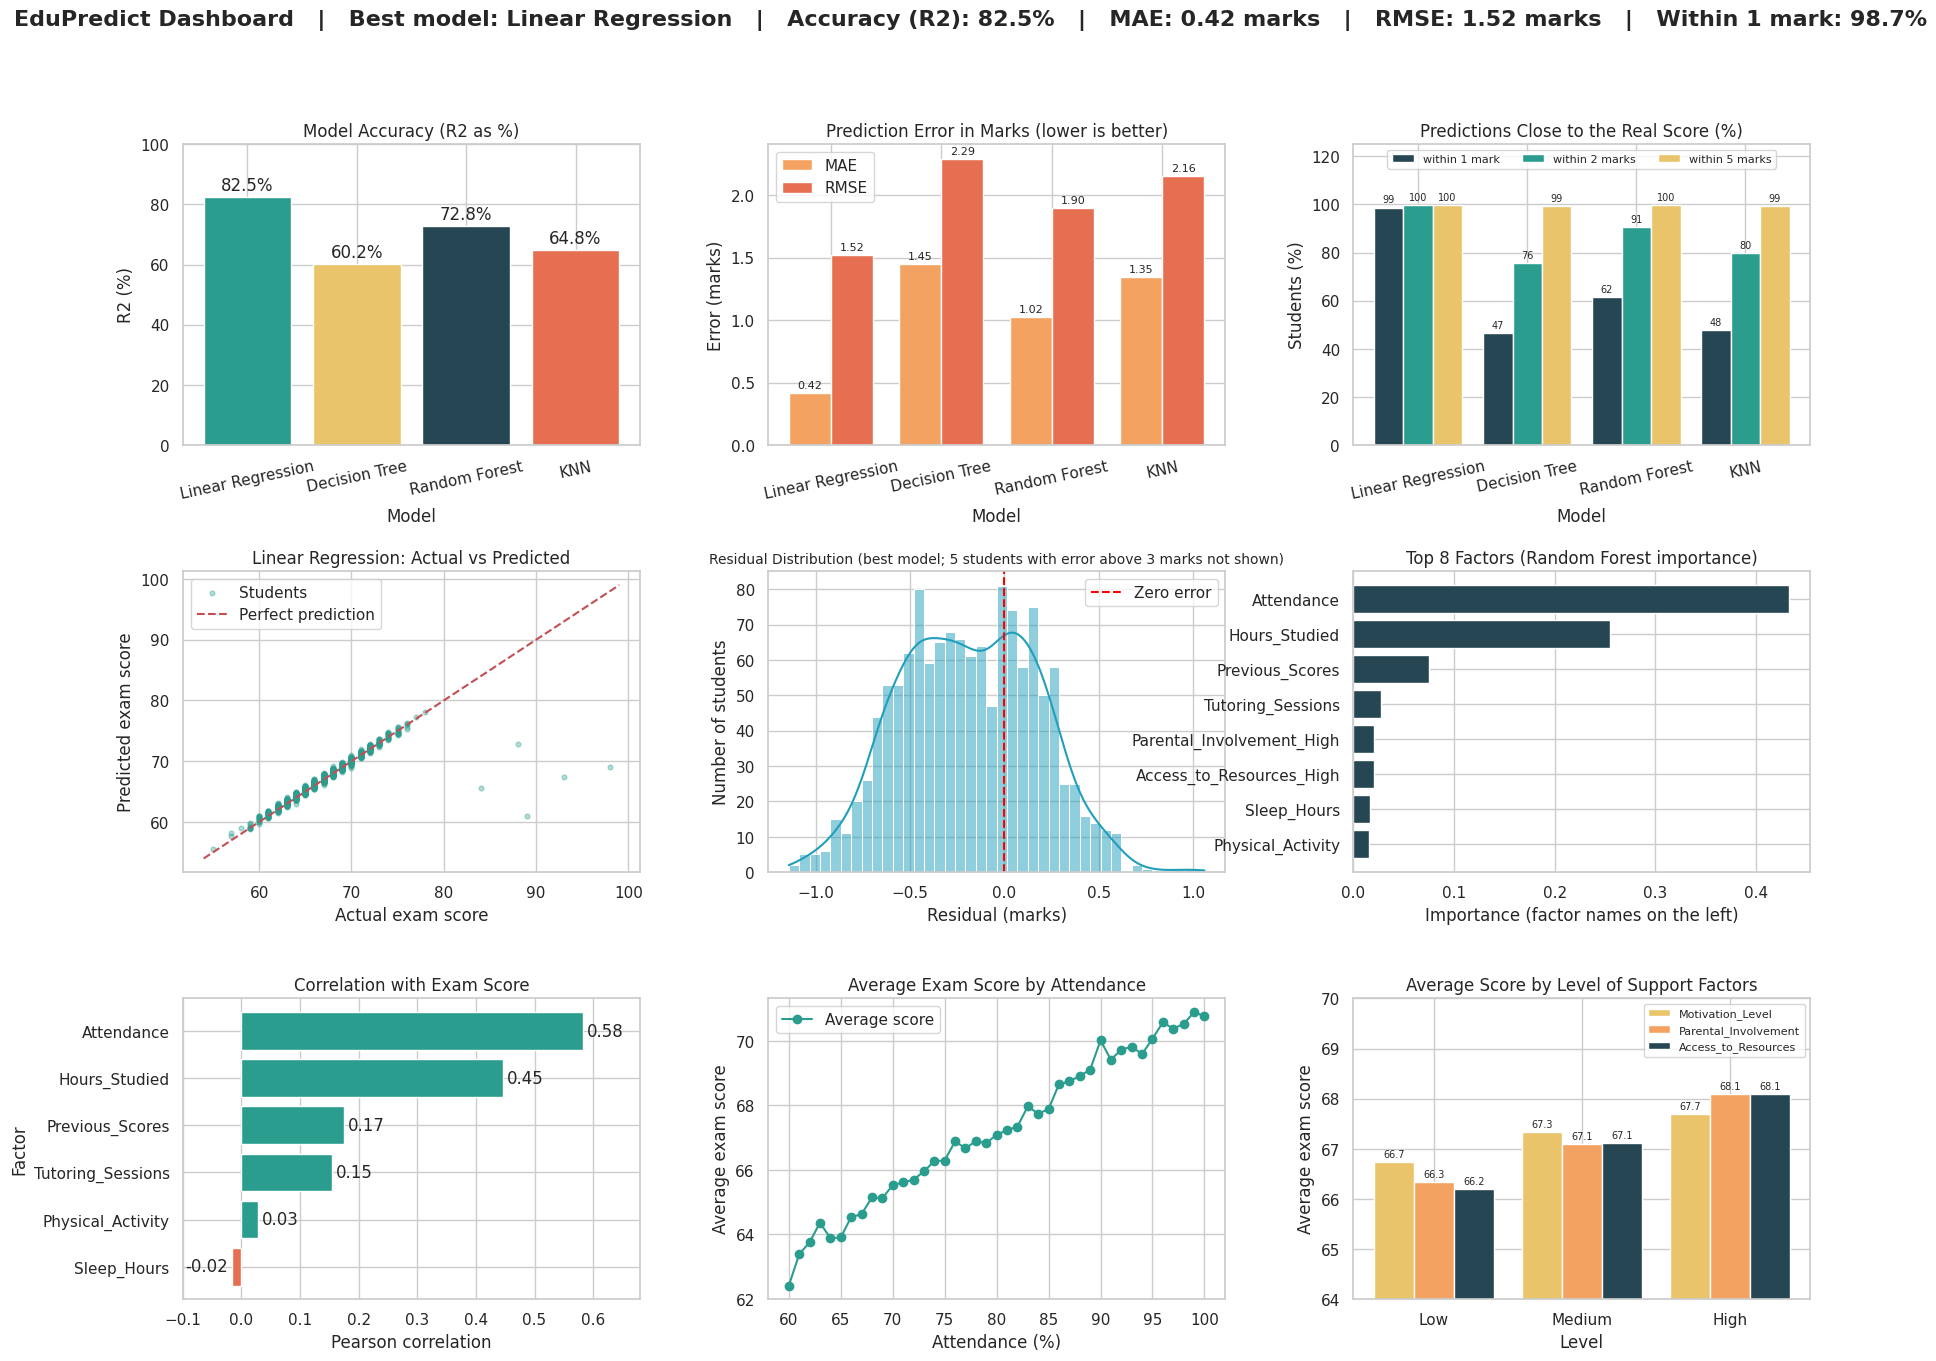

In [44]:
model_colors = {'Linear Regression': '#2a9d8f', 'Decision Tree': '#e9c46a', 'Random Forest': '#264653', 'KNN': '#e76f51'}
fig = plt.figure(figsize=(21, 15))
grid = fig.add_gridspec(3, 3, hspace=0.42, wspace=0.28)
best_row = comparison.loc[best_name]
fig.suptitle(f"EduPredict Dashboard   |   Best model: {best_name}   |   Accuracy (R2): {best_row['R2'] * 100:.1f}%   |   "
             f"MAE: {best_row['MAE']:.2f} marks   |   RMSE: {best_row['RMSE']:.2f} marks   |   "
             f"Within 1 mark: {tolerance.loc[best_name, 'within 1 mark']:.1f}%", fontsize=16, fontweight='bold', y=0.97)

# Row 1: model comparison
ax = fig.add_subplot(grid[0, 0])
bars = ax.bar(comparison.index, comparison['R2'] * 100, color=[model_colors[m] for m in comparison.index])
ax.bar_label(bars, fmt='%.1f%%', padding=2)
ax.set_ylim(0, 100); ax.set_title('Model Accuracy (R2 as %)'); ax.set_xlabel('Model'); ax.set_ylabel('R2 (%)')
ax.tick_params(axis='x', rotation=12)

ax = fig.add_subplot(grid[0, 1])
positions = np.arange(len(comparison))
for i, (metric, color) in enumerate([('MAE', '#f4a261'), ('RMSE', '#e76f51')]):
    bars = ax.bar(positions + i * 0.38 - 0.19, comparison[metric], 0.38, label=metric, color=color)
    ax.bar_label(bars, fmt='%.2f', fontsize=8, padding=2)
ax.set_xticks(positions); ax.set_xticklabels(comparison.index, rotation=12)
ax.set_title('Prediction Error in Marks (lower is better)'); ax.set_xlabel('Model'); ax.set_ylabel('Error (marks)'); ax.legend()

ax = fig.add_subplot(grid[0, 2])
for i, (col, color) in enumerate(zip(tolerance.columns, ['#264653', '#2a9d8f', '#e9c46a'])):
    bars = ax.bar(positions + i * 0.27 - 0.27, tolerance[col], 0.27, label=col, color=color)
    ax.bar_label(bars, fmt='%.0f', fontsize=7, padding=2)
ax.set_xticks(positions); ax.set_xticklabels(comparison.index, rotation=12); ax.set_ylim(0, 125)
ax.set_title('Predictions Close to the Real Score (%)'); ax.set_xlabel('Model'); ax.set_ylabel('Students (%)'); ax.legend(fontsize=8, ncol=3, loc='upper center')

# Row 2: best model behaviour and drivers
ax = fig.add_subplot(grid[1, 0])
ax.scatter(y_test, best_predictions, alpha=0.35, s=12, color='#2a9d8f', label='Students')
limits = [y_test.min() - 1, y_test.max() + 1]
ax.plot(limits, limits, 'r--', label='Perfect prediction')
ax.set_title(f'{best_name}: Actual vs Predicted'); ax.set_xlabel('Actual exam score'); ax.set_ylabel('Predicted exam score'); ax.legend()

ax = fig.add_subplot(grid[1, 1])
shown = residuals[residuals.abs() <= 3]      # focus on the main body; the few very large errors are counted in the title
sns.histplot(shown, bins=40, kde=True, color='#219ebc', ax=ax)
ax.axvline(0, color='red', linestyle='--', label='Zero error')
ax.set_title(f'Residual Distribution (best model; {len(residuals) - len(shown)} students with error above 3 marks not shown)', fontsize=10); ax.set_xlabel('Residual (marks)'); ax.set_ylabel('Number of students'); ax.legend()

ax = fig.add_subplot(grid[1, 2])
top_importance = forest_importance.sort_values().tail(8)
ax.barh(top_importance.index, top_importance.values, color='#264653')
ax.set_title('Top 8 Factors (Random Forest importance)'); ax.set_xlabel('Importance (factor names on the left)')

# Row 3: key relationships from the EDA
ax = fig.add_subplot(grid[2, 0])
correlations = df_eda[numeric_features].corrwith(df_eda['Exam_Score']).sort_values()
bars = ax.barh(correlations.index, correlations.values, color=['#e76f51' if v < 0 else '#2a9d8f' for v in correlations.values])
ax.bar_label(bars, fmt='%.2f', padding=3); ax.set_xlim(-0.1, 0.68)
ax.set_title('Correlation with Exam Score'); ax.set_xlabel('Pearson correlation'); ax.set_ylabel('Factor')

ax = fig.add_subplot(grid[2, 1])
average_by_attendance = df_eda.groupby('Attendance')['Exam_Score'].mean()
ax.plot(average_by_attendance.index, average_by_attendance.values, marker='o', color='#2a9d8f', label='Average score')
ax.set_title('Average Exam Score by Attendance'); ax.set_xlabel('Attendance (%)'); ax.set_ylabel('Average exam score'); ax.legend()

ax = fig.add_subplot(grid[2, 2])
levels = ['Low', 'Medium', 'High']
for i, (factor, color) in enumerate(zip(['Motivation_Level', 'Parental_Involvement', 'Access_to_Resources'], ['#e9c46a', '#f4a261', '#264653'])):
    means = df_eda.groupby(factor)['Exam_Score'].mean().reindex(levels)
    bars = ax.bar(np.arange(3) + i * 0.27 - 0.27, means.values, 0.27, label=factor, color=color)
    ax.bar_label(bars, fmt='%.1f', fontsize=7, padding=2)
ax.set_xticks(range(3)); ax.set_xticklabels(levels); ax.set_ylim(64, 70)
ax.set_title('Average Score by Level of Support Factors'); ax.set_xlabel('Level'); ax.set_ylabel('Average exam score'); ax.legend(fontsize=8)

plt.savefig(GRAPHS / '20_dashboard.png', dpi=110, bbox_inches='tight')
plt.show()

## Phase 8: Key findings, recommendations and conclusion

### Key findings (all from the analysis above)
1. **Data quality:** 6,607 records and 20 columns. Three categorical columns had a few missing values (78, 90 and 67), filled with the most frequent value inside the pipeline. There were no duplicates and no inconsistent category labels. One impossible `Exam_Score` of 101 was removed. IQR outliers were valid values and were kept.
2. **Exam scores** are concentrated (mean about 67.2, standard deviation about 3.9, range 55 to 100).
3. **Attendance** has the strongest association with exam score (r = 0.58, about 0.2 marks per attendance point; averages of about 62 at 60 percent and 71 at 100 percent attendance).
4. **Study hours** come second (r = 0.45, about 0.29 marks per weekly hour).
5. **Previous scores** have only a weak association (r = 0.17) in this dataset.
6. **Sleep** shows no meaningful association (r = -0.02). **Tutoring** shows a small positive association (r = 0.15; about 66.5 marks with no tutoring versus about 69 with five or more sessions).
7. **Parental involvement, access to resources and motivation** are linked to differences of about 1.8, 1.9 and 1.0 marks between high and low levels. Gender and school type show essentially no difference.
8. **Combined effect:** high study hours plus high attendance average about 72 marks versus about 62 for low study plus low attendance.
9. **Best model:** **Linear Regression** (test R² 0.825, MAE 0.42, MSE 2.31, RMSE 1.52). Order: Linear Regression > Random Forest (0.728) > KNN (0.648) > Decision Tree (0.602). The order is the same under cross-validation.
10. **Model reliability:** 98.6 percent of students are predicted within 1 mark. About 0.7 percent (49 students) have scores far above what any recorded feature explains, which is what keeps R² below 0.9.

### Recommendations
**For students:** attend classes regularly (the strongest factor), keep a steady weekly study routine, use tutoring if available (small positive association), and do not rely on sleeping fewer or more hours as a score lever in itself (no association found here, though this does not mean sleep is unimportant for health).

**For institutions:** monitor attendance as an early-warning indicator; support families to be involved; make learning resources accessible to all students; offer tutoring support, especially for students with low attendance and low study time; use the model as a *support* tool to identify students who may need help early, never as a basis for labelling or penalising students.

### Limitations
- The relationships are **associations, not proven causes**. For example, motivated students may both attend more and score more.
- The dataset is **very regular**: tidy ranges, near-independent features and a nearly straight-line relationship for 99 percent of students. This suggests it may be simulated or heavily processed rather than raw school records (the source does not allow us to confirm this). Results may therefore not carry over to real classrooms, where prediction is usually much harder.
- About 0.7 percent of students have scores that none of the features explains; we kept them since we could not prove they were errors.
- The score is a single exam; the data has no time dimension, subject, or information on how it was collected. Sleep is recorded as hours only, not quality.
- Models were lightly tuned (cross-validation on a few settings) to keep the project simple.

### Future scope
Add real institutional data and more features (assignment marks, subject, semester); try tuned gradient-boosting models and compare with cross-validated results; add confidence ranges to predictions; study fairness across groups; deploy the Streamlit app online.

### Conclusion
Using the real Student Performance Factors dataset, we cleaned the data, performed EDA, investigated five objectives, engineered meaningful features, trained four regression models with a shared train-test split and compared them with R², MAE, MSE and RMSE. **Linear Regression** is the best-fit model, and attendance and study hours are the most important factors. The trained pipeline is saved in `models/best_model.pkl` and used by the Streamlit app `app.py`.

### Teacher's rubric compliance

| # | Requirement | How it was completed | Where |
|---|---|---|---|
| 1 | Download a relevant dataset | Kaggle "Student Performance Factors" (6,607 rows, 20 columns), used as downloaded | `dataset/StudentPerformanceFactors.csv`; Phase 1 |
| 2 | Preprocessing and cleaning (missing values, duplicates, inconsistent data) | Missing values found in 3 columns and imputed (pipeline); 0 duplicates; categories checked; invalid score 101 removed; outliers reviewed with box plots and IQR | Phase 2 |
| 3 | EDA with meaningful insights | Univariate, bivariate and multivariate analysis with histograms, count plots, box plots, scatter plots, heatmap, pair plot | Phase 3 |
| 4 | At least five objectives | Five objectives: study hours, attendance, previous scores, sleep and tutoring, categorical factors | Phase 3 (Objectives 1 to 5) |
| 5 | Appropriate visualisation | 20 labelled graphs including a one-page dashboard with titles, axis labels, legends and interpretations | `outputs/graphs/` |
| 6 | Feature engineering | `Study_Category`, `Attendance_Category`, `Sleep_Category` (for analysis; originals kept for modelling; no leakage) | Phase 4 |
| 7 | At least four ML models | Linear Regression, Decision Tree, Random Forest, KNN in scikit-learn pipelines, same split, `random_state=42` | Phase 5 |
| 8 | Identify best-fit model | Selected by test-set R² and confirmed by cross-validation: Linear Regression | Phase 6 |
| 9 | Appropriate metrics | R², MAE, MSE, RMSE plus residual analysis and feature importance | Phase 6 |
| 10 | Findings, conclusions, recommendations | Key findings, recommendations, limitations, future scope | Phase 8 |